# 09 — Modelos supervisados para `sin_camara`

**Plan de notebooks, uno por número.** El 07 justifica el target; el 08 analiza los datos del target elegido; **el 09 (este) entrena, ajusta, compara e interpreta los modelos supervisados**; el 10 evalúa en el test y cierra (no existe todavía y no se abre acá).

**Qué hacemos acá.** Entrenamos regresión logística, HGB y un Random Forest para predecir `sin_camara` (cajas 3D etiquetadas de peatones y ciclistas dentro de la zona de cámaras sin su par 2D) en la **población principal** de train (peatones y ciclistas con |azimut| ≤ `AZ_MAX` = 100°; la población de 120° queda como sensibilidad en la sección H), con los folds ya definidos.
Todo es fuera de fold y la elección de hiperparámetros es anidada (validación interna agrupada por segmento). Es insumo del 10: dejamos los modelos finales ajustados sobre todo train y los umbrales fijados **con train**, sin evaluarlos en test.

**Reglas.** Solo segmentos de train; **no se carga `test.parquet` ni ningún dato de los 8 segmentos de test** (hay asserts). Todas las cifras se calculan en el notebook y las conclusiones son f-strings. Los criterios de la celda siguiente se fijaron **antes de correr** y no se cambian.

**Entradas:** `features_B.parquet` y `config_features_B.json` (del 08), `config_features.json` (solo la lista de ids de los segmentos de test, para los asserts).
**Salidas:** `images/09_*.png`, `data/08_reporting/09_*.csv`, `docs/modelos_supervisados_B.md`, `docs/entorno_ep2.txt`, `data/07_model_output/oof_B.parquet`, `data/06_models/hiperparametros_B.json`, `lr_B.joblib` y `hgb_B.joblib`.

<a id="resumen"></a>
## Resumen ejecutivo

*(Texto generado por la celda "Resumen ejecutivo generado" en la última ejecución; se copia acá para leerlo arriba. Si se vuelve a ejecutar el notebook, hay que volver a copiarlo.)*

**Resultado.** **Recomendación final: Regla: menos puntos top.** Ningún modelo es robusto frente al mejor baseline simple: el mejor modelo (Regresion logistica) no vale la pena en la población principal y no vale la pena en la de 120°. Se recomienda el baseline simple **Regla: menos puntos top** por simplicidad y explicabilidad; los modelos quedan como comparación. En la población principal el mejor modelo (Regresion logistica) tiene AUC 0,825, PR-AUC 0,657, Captura@20 % 58,1 % y Fracción para 80 % 43,7 %; el baseline (Regla: menos puntos top), AUC 0,862 y Fracción para 80 % 37,8 %. Diferencia modelo menos baseline: AUC -0.036 (IC -0.056 a -0.007) y Fracción para 80 % +5.8 puntos (IC -0.8 a +10.6).

**Puntos clave**

1. Estabilidad del mejor modelo (Regresion logistica): AUC mínimo por fold 0,811 y mediana del AUC por segmento 0,888 → cumple los umbrales fijados.
2. Punto A (recall 0,80 fijado con train, mejor modelo Regresion logistica): recall 0,810 (IC 0,761 a 0,874), precisión 0,431, 38,9 % de los frames a revisar; el baseline (Regla: menos puntos top) con el mismo método revisa el 37,9 % para un recall de 0,806.
3. Calibración: ECE crudo 0,044; mejor versión Platt con ECE 0,013 (cumple el umbral de 0,05).
4. Sensibilidad (población de 120°, 68.555 filas): mejor baseline simple Regla geometrica (azimut > 105 primero); modelos que valen la pena frente a él: ninguno; robustos: ninguno.
5. Diagnóstico (C.2): la brecha agrupada de AUC entre modelo y regla de puntos es mucho mayor que la brecha por fold y por segmento; por fold y por segmento los IC incluyen 0 para Regresion logistica, HGB, Random Forest, así que **el modelo no se distingue de la regla de puntos**. Frente al mejor baseline simple (Regla: menos puntos top): Regresion logistica: el modelo no se distingue de la regla; HGB: la evidencia es mixta (un IC incluye 0 y el otro no); Random Forest: el modelo no se distingue de la regla. El veredicto de los criterios fijados antes (frente al mejor baseline simple: Regresion logistica: no vale la pena, HGB: no vale la pena, Random Forest: no vale la pena) no cambia: lo que cambia es su alcance, porque «no vale la pena» no equivale a «es peor».

**Limitaciones**

- La etiqueta mide cobertura de etiquetado, no visibilidad física de la cámara.
- La población principal (|azimut| ≤ 100°) excluye 4.046 filas (5,9 %) cuya ausencia de par 2D es en buena parte geométrica; el borde de 100° es empírico y no se pudo confirmar con la calibración de las cámaras (`camera_calibration` no está disponible localmente).
- Pocos ciclistas (1.483 filas en la población principal): las métricas por clase son frágiles.
- La búsqueda de hiperparámetros es acotada: Regresion logistica: 16, 16, 16, 16, 16 configuraciones reales por fold (ajuste final: 16); HGB: 12, 12, 12, 12, 12 configuraciones reales por fold (ajuste final: 12); Random Forest: 6, 6, 6, 6, 6 configuraciones reales por fold (ajuste final: 6). Es una búsqueda aleatoria sobre un espacio limitado (con grilla para la regresión logística), no exhaustiva.

Este notebook no abre el test; deja modelos, umbrales y calibrador listos para el 10.

## Lecturas tomadas (decisiones sin consulta)

Este notebook se construyó sin poder consultar. Ante cada ambigüedad se tomó la lectura más razonable:

1. **Búsqueda anidada con tiempo acotado.** Cada búsqueda aleatoria evalúa hasta 20 configuraciones, pero se corta cuando pasa un presupuesto de tiempo por búsqueda (hay 5 búsquedas externas más una final por modelo). Si no alcanza, se reduce el número de configuraciones y el notebook lo informa.
2. **Early stopping agrupado del HGB.** No se usa el early stopping interno de scikit-learn (parte al azar, no por segmento); `max_iter` se elige con la curva de PR-AUC de la validación interna agrupada, evaluada cada 10 iteraciones hasta un tope.
3. **Umbrales "con datos de entrenamiento del fold".** Se eligen sobre predicciones **fuera de fold internas** (validación interna agrupada) de los segmentos de entrenamiento, no sobre predicciones del propio ajuste (que son optimistas). Punto B (presupuesto de revisión): corte en el percentil 80 de esas predicciones internas, así que la fracción revisada es aproximadamente 20 %, no exacta.
4. **Calibración anidada.** Platt e isotónica se ajustan sobre las predicciones internas fuera de fold de los segmentos de entrenamiento y se aplican al fold de validación.
5. **Sensibilidad (sección H).** Se reentrena solo con |azimut| ≤ 100 usando los hiperparámetros ya elegidos, sin volver a buscarlos.
6. **Segmentos evaluables para recall por segmento:** los que tienen al menos 50 frames `sin_camara`.
7. **SMOTE y SHAP:** `imbalanced-learn` y `shap` no están instalados y no se instalan; se omiten y el notebook lo dice.
8. **Nueva pasada (población y baselines).** La población principal pasa de 120° a **`AZ_MAX` = 100°** por el hallazgo de A.6 del 08 (la tasa de `sin_camara` sube a 62,2 % en 100–120°); el target y el split no cambian. La población de 120° se reporta como sensibilidad (sección H).
9. **Regla geométrica:** primero las cajas con azimut > 105°, dentro de cada grupo menos puntos LiDAR primero. En la población principal ninguna fila tiene azimut > 105°, así que es **idéntica a la regla de puntos**; solo se distingue en la sensibilidad de 120°.
10. **Modelo mínimo:** regresión logística con `log1p(num_lidar_points)`, `log1p(num_top_lidar_points)` y `azimut_abs_deg`, con C = 1 (sin ajuste de hiperparámetros), ajustada dentro de cada fold.
11. **Mejor baseline simple:** el de mayor AUC fuera de fold entre la regla de puntos, la regla geométrica y el modelo mínimo (los empates se resuelven por ese orden). Los criterios "vale la pena" se comparan contra él.
12. **Mejor modelo vs recomendación final.** Las secciones D a G analizan el mejor modelo aprendido (regresión logística, HGB o Random Forest, según el criterio de elección). La **recomendación final** es ese modelo solo si es *robusto*; si no, es el mejor baseline simple (sección I).
13. **Random Forest:** hasta 6 configuraciones (las mismas en todos los folds), 200 árboles y sin `class_weight`; se ejecuta al final y se **recorta** (se omite) si el notebook ya lleva más de 60 minutos al llegar a él, para no pasar de 90 minutos en total.
14. **Diagnóstico de la métrica agrupada (sección C.2).** El AUC agrupado mezcla las predicciones de cinco modelos distintos (uno por fold, con hiperparámetros distintos), mientras que la regla no tiene esa fuente de variación; además cada fold tiene su propia escala de probabilidades. Se agrega como **diagnóstico** (por fold, por segmento y con rangos percentiles dentro de cada fold); **no cambia los criterios fijados antes ni su aplicación**, solo aclara su alcance.
15. **Baselines:** la regla por puntos top (`num_top_lidar_points`) entra a la lista de baselines simples (al final de la lista, que fija los desempates). El mejor baseline simple se recalcula en la población principal y en la de 120°, y los criterios "vale la pena" y "robusto" se aplican contra él.
16. **Búsqueda más justa.** No es una nueva familia de modelos: (a) la regresión logística eligió el borde inferior de la grilla de C (1e-3) en 3 de 5 folds y en el ajuste final, así que la grilla se extiende a 1e-5 y 1e-4; (b) el HGB quedó limitado por el presupuesto de tiempo a 5 configuraciones por fold, así que se hacen hasta 12 configuraciones reales por fold (el notebook informa cuántas evaluó de verdad) y el espacio se amplía hacia modelos simples (hojas, profundidad, `min_samples_leaf` y regularización) con una restricción monótona decreciente opcional en `num_lidar_points`, `num_top_lidar_points` y `densidad_puntos`; (c) el Random Forest usa 6 configuraciones fijas con profundidades menores.
17. **Plan de evaluación del test (sección J).** Solo archivos: no se carga ningún dato de test. Lo único que se lee del test es la tabla de conteos por segmento que escribe el notebook 07 (`07_conteos_test.csv`). Los modelos congelados se entrenaron en la población principal y se evalúan en ambas poblaciones; la regla geométrica se incluye porque forma parte de la lista de baselines simples.
18. **Mejor baseline en test:** como en train, el mejor baseline simple de la población evaluada es el de mayor AUC en esa población; el plan también pide mostrar la comparación contra el baseline elegido en train, por transparencia.

## Criterios fijados antes de correr

Los KPIs vienen de la Sección 8.7 del 07; los umbrales se justifican por el uso (priorizar revisión humana) y no por los resultados de este notebook.

- **Baselines:** (a) clasificador trivial (prevalencia); (b) **regla de puntos** (menos puntos LiDAR primero); (c) **regla geométrica** (primero azimut > 105°, dentro de cada grupo menos puntos primero); (d) **modelo mínimo** (regresión logística con `log1p(num_lidar_points)`, `log1p(num_top_lidar_points)` y `azimut_abs_deg`). El **mejor baseline simple** es el de mayor AUC entre (b), (c) y (d) en la población que se evalúa.
- **"Vale la pena" frente al mejor baseline simple:** la Fracción para 80 % baja ≥ 5 puntos con IC 95 % por segmentos (bootstrap pareado) que excluya 0, **y** el AUC sube ≥ 0,03.
- **Robusto:** un modelo es robusto si "vale la pena" en la población principal (|azimut| ≤ 100°) **y** en la de sensibilidad (≤ 120°), cada una frente al mejor baseline simple de esa población. La recomendación final es el modelo elegido por la prueba entre modelos solo si es robusto; si no, es el mejor baseline simple.
- **Elección entre modelos:** si el HGB mejora a la regresión logística en AUC ≥ 0,01 y en Fracción para 80 %, ambos con IC pareado que excluya 0, el HGB es el recomendado; si no, se declaran equivalentes y se recomienda la regresión logística por interpretabilidad (el HGB queda como comparación). Si el Random Forest pasa la misma prueba contra el mejor, se aplica igual.
- **Estabilidad:** AUC mínimo por fold ≥ 0,75 y mediana del AUC por segmento (segmentos evaluables como en el 08) ≥ 0,80.
- **Punto A (recall objetivo 0,80)** y **punto B (revisar el 20 % mejor puntuado)**, con referencia de **máximo F1**; el umbral nunca se elige con el fold que se evalúa.
- **Calibración "aceptable":** ECE ≤ 0,05 tras calibrar.

In [1]:
CRIT = {
    "vale_la_pena": {"delta_fraccion80_max": -0.05, "delta_auc_min": 0.03},
    "eleccion": {"delta_auc_min": 0.01},
    "estabilidad": {"auc_fold_min": 0.75, "auc_segmento_mediana_min": 0.80, "min_filas_clase_segmento": 200, "min_segmentos": 10, "min_filas_clase_relajado": 100},
    "operacion": {"recall_objetivo": 0.80, "presupuesto_revision": 0.20, "recall_segmento_min": 0.75, "min_positivos_segmento": 50},
    "calibracion": {"ece_max": 0.05},
    "poblacion": {"AZ_MAX": 100, "umbral_regla_geometrica_deg": 105},
    "robusto": "vale la pena en la poblacion principal y en la de sensibilidad (120 grados), frente al mejor baseline simple de cada una",
}
print(CRIT)

{'vale_la_pena': {'delta_fraccion80_max': -0.05, 'delta_auc_min': 0.03}, 'eleccion': {'delta_auc_min': 0.01}, 'estabilidad': {'auc_fold_min': 0.75, 'auc_segmento_mediana_min': 0.8, 'min_filas_clase_segmento': 200, 'min_segmentos': 10, 'min_filas_clase_relajado': 100}, 'operacion': {'recall_objetivo': 0.8, 'presupuesto_revision': 0.2, 'recall_segmento_min': 0.75, 'min_positivos_segmento': 50}, 'calibracion': {'ece_max': 0.05}, 'poblacion': {'AZ_MAX': 100, 'umbral_regla_geometrica_deg': 105}, 'robusto': 'vale la pena en la poblacion principal y en la de sensibilidad (120 grados), frente al mejor baseline simple de cada una'}


## Configuración, versiones y carga

In [2]:
from pathlib import Path
import json
import platform
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.stats import loguniform
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import partial_dependence
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, ParameterSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

try:
    RAIZ = Path(context.project_path)
except NameError:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists())

RUTA_IMAGENES, RUTA_MODEL_INPUT = RAIZ / "images", RAIZ / "data" / "05_model_input"
RUTA_REPORTING, RUTA_DOCS = RAIZ / "data" / "08_reporting", RAIZ / "docs"
RUTA_MODELOS, RUTA_SALIDA = RAIZ / "data" / "06_models", RAIZ / "data" / "07_model_output"
for d in (RUTA_IMAGENES, RUTA_REPORTING, RUTA_MODELOS, RUTA_SALIDA):
    d.mkdir(parents=True, exist_ok=True)

versiones = (f"Python {sys.version.split()[0]}\npandas {pd.__version__}\nnumpy {np.__version__}\nscikit-learn {sklearn.__version__}\nscipy {scipy.__version__}\njoblib {joblib.__version__}\n"
             f"plataforma {platform.platform()}\nsemilla {SEMILLA}\n")
(RUTA_DOCS / "entorno_ep2.txt").write_text(versiones, encoding="utf-8")
print(versiones)
try:
    import imblearn
    HAY_IMBLEARN = True
except ImportError:
    HAY_IMBLEARN = False
try:
    import shap
    HAY_SHAP = True
except ImportError:
    HAY_SHAP = False
print(f"imbalanced-learn instalado: {HAY_IMBLEARN} | shap instalado: {HAY_SHAP} (no se instala nada; lo que falta se omite)")


def guardar_fig(fig, nombre):
    fig.savefig(RUTA_IMAGENES / f"{nombre}.png", dpi=150, bbox_inches="tight")


def pct(x, d=1):
    return f"{x * 100:.{d}f} %".replace(".", ",")


def n2(x, d=2):
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    return f"{int(x):,}".replace(",", ".")


def md_tabla(df, indice=True):
    d = df.reset_index() if indice else df
    cab = "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n"
    return cab + "\n".join("| " + " | ".join(str(v) for v in fila) + " |" for fila in d.values)


AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"
RES, TIEMPOS = {}, {}
T_INICIO = time.time()
LIM_RF_S = 60 * 60       # el Random Forest se omite si el notebook ya lleva mas de 60 minutos al llegar a el (limite total de 90 minutos)

Python 3.10.11
pandas 2.3.3
numpy 2.2.6
scikit-learn 1.7.2
scipy 1.15.3
joblib 1.5.3
plataforma Windows-10-10.0.26300-SP0
semilla 42

imbalanced-learn instalado: False | shap instalado: False (no se instala nada; lo que falta se omite)


# A. Preparación y línea base

**Por qué importa.** Antes de entrenar hay que fijar con qué datos y contra qué se compara. Verificamos la población, los folds y que no entren variables prohibidas, y definimos las referencias sin modelo.

In [3]:
cfgB = json.loads((RUTA_MODEL_INPUT / "config_features_B.json").read_text(encoding="utf-8"))
cfg06 = json.loads((RUTA_MODEL_INPUT / "config_features.json").read_text(encoding="utf-8"))
SEGS_TEST = set(cfg06["segmentos_test"])               # solo la lista de ids, para los asserts; nunca se carga un dato de test
df_full = pd.read_parquet(RUTA_MODEL_INPUT / "features_B.parquet")          # toda B (|azimut| <= 120): poblacion de sensibilidad
AZ_MAX = cfgB["AZ_MAX"]
assert AZ_MAX == CRIT["poblacion"]["AZ_MAX"]
GRUPO, TARGET = cfgB["grupo"], "sin_camara"
VARS = cfgB["recomendado_09"]["variables"]
COLS_EVAL = cfgB["cols_evaluacion_no_variables"]
IDS = cfgB["cols_id"]

# --- asserts de reglas
assert set(df_full[GRUPO]).isdisjoint(SEGS_TEST), "hay segmentos de test en los datos"
assert len(df_full) == cfgB["n_filas"] and df_full[GRUPO].nunique() == cfgB["n_segmentos"] and df_full["fold"].nunique() == cfgB["n_folds"], "la poblacion no coincide con config_features_B.json"
assert not set(COLS_EVAL) & set(VARS), "time_of_day o location entran como variables"
assert not [v for v in VARS if any(p in v.lower() for p in ("tiene_", "asoc", "camara", "camera"))], "variable con nombre de camara"
assert "test.parquet" not in str(RUTA_MODEL_INPUT / "features_B.parquet")
assert (df_full.groupby(GRUPO)["fold"].nunique() == 1).all(), "un segmento aparece en dos folds"
assert "en_zona_principal" in df_full.columns and (df_full["en_zona_principal"] == (df_full["azimut_abs_deg"] <= AZ_MAX)).all(), "en_zona_principal no coincide con AZ_MAX"
df = df_full[df_full["en_zona_principal"]].reset_index(drop=True)          # POBLACION PRINCIPAL
print(f"Poblacion principal (|azimut| <= {AZ_MAX}): {len(df):,} filas de {len(df_full):,} | {df[GRUPO].nunique()} segmentos | folds {sorted(df['fold'].unique())} | prevalencia de sin_camara {df[TARGET].mean():.3f} (poblacion de 120: {df_full[TARGET].mean():.3f}) | {len(VARS)} variables")
print("Controles OK: sin segmentos de test, time_of_day/location fuera de las variables, ninguna variable con tiene_/asoc/camara.")

y = df[TARGET].values
folds = df["fold"].values.astype(int)
FOLDS = sorted(np.unique(folds))
X = df[VARS].copy()
grupos = df[GRUPO].values
seg_codes, seg_nombres = pd.factorize(df[GRUPO])
S_N = len(seg_nombres)
idx_seg = [np.where(seg_codes == s)[0] for s in range(S_N)]
tb_f = np.random.default_rng(SEMILLA).random(len(df))      # desempate aleatorio fijo para empates de puntaje
tabla_folds = df.groupby("fold").agg(filas=(TARGET, "size"), segmentos=(GRUPO, "nunique"), prevalencia=(TARGET, "mean")).round(3)
print(tabla_folds.to_string())

Poblacion principal (|azimut| <= 100): 64,509 filas de 68,555 | 33 segmentos | folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | prevalencia de sin_camara 0.207 (poblacion de 120: 0.232) | 16 variables
Controles OK: sin segmentos de test, time_of_day/location fuera de las variables, ninguna variable con tiene_/asoc/camara.
      filas  segmentos  prevalencia
fold                               
0      6374          5        0.199
1      9290          7        0.168
2     15526          7        0.287
3     17006          8        0.173
4     16313          6        0.192


In [4]:
# ---- Funciones de evaluacion (mismas curvas de captura y bootstrap por segmento que el 07 y el 08)
def curva_cap(peso, score, tb):
    o = np.lexsort((tb, -score))
    return np.cumsum(peso[o]) / peso.sum()


def metr(cum):
    n = len(cum)
    en = lambda f: cum[max(int(np.ceil(f * n)) - 1, 0)]
    return {"Captura@20%": en(0.2), "Lift@20%": en(0.2) / 0.2, "Fraccion para 80%": (np.searchsorted(cum, 0.8) + 1) / n}


def metricas_score(y_, s, tb):
    if len(np.unique(y_)) < 2:
        return {"AUC": np.nan, "PR-AUC": np.nan, "Captura@20%": np.nan, "Fraccion para 80%": np.nan}
    m = metr(curva_cap(y_.astype(float), s, tb))
    return {"AUC": roc_auc_score(y_, s), "PR-AUC": average_precision_score(y_, s), "Captura@20%": m["Captura@20%"], "Fraccion para 80%": m["Fraccion para 80%"]}


MET = ["AUC", "PR-AUC", "Captura@20%", "Fraccion para 80%"]


def boot_all(scores, mask=None, n_boot=300, seed=SEMILLA, pob=None):
    # Puntos y arreglos remuestreados (bootstrap de segmentos) de las metricas de cada puntaje; `mask` restringe a un subconjunto de filas
    # y `pob` permite evaluar otra poblacion (dict con y, tb, seg, n_seg), por ejemplo la de sensibilidad de 120 grados.
    Y, TB, SC, NS = (y, tb_f, seg_codes, S_N) if pob is None else (pob["y"], pob["tb"], pob["seg"], pob["n_seg"])
    ii0 = np.arange(len(Y)) if mask is None else np.where(mask)[0]
    y_, tb_ = Y[ii0], TB[ii0]
    segs = [a for a in (np.where(SC[ii0] == s)[0] for s in range(NS)) if len(a)]
    rng = np.random.default_rng(seed)
    punto = {n: metricas_score(y_, sc[ii0], tb_) for n, sc in scores.items()}
    boot = {n: {m: [] for m in MET} for n in scores}
    for _ in range(n_boot):
        ii = np.concatenate([segs[j] for j in rng.integers(0, len(segs), len(segs))])
        if len(np.unique(y_[ii])) < 2:
            continue
        for n, sc in scores.items():
            r = metricas_score(y_[ii], sc[ii0][ii], tb_[ii])
            for m in MET:
                boot[n][m].append(r[m])
    return punto, {n: {m: np.array(v) for m, v in d.items()} for n, d in boot.items()}


def ic(arr):
    return tuple(np.percentile(arr, [2.5, 97.5]))


def delta(punto, boot, a, b, met):
    # a menos b: valor y IC 95% pareado por segmentos
    d = boot[a][met] - boot[b][met]
    return punto[a][met] - punto[b][met], *np.percentile(d, [2.5, 97.5])


def por_segmento_auc(score, mask=None):
    crit = CRIT["estabilidad"]
    out = []
    for si in range(S_N):
        ii = idx_seg[si] if mask is None else idx_seg[si][mask[idx_seg[si]]]
        n1, n0 = int(y[ii].sum()), int((1 - y[ii]).sum())
        out.append((seg_nombres[si], len(ii), n1, n0, roc_auc_score(y[ii], score[ii]) if min(n1, n0) > 1 else np.nan))
    t = pd.DataFrame(out, columns=["segmento", "filas", "sin", "con", "auc"])
    minimo = crit["min_filas_clase_segmento"]
    ev = t[(t["sin"] >= minimo) & (t["con"] >= minimo)]
    if len(ev) < crit["min_segmentos"]:
        minimo = crit["min_filas_clase_relajado"]
        ev = t[(t["sin"] >= minimo) & (t["con"] >= minimo)]
    return t, ev, minimo
print("Funciones de evaluacion definidas.")

Funciones de evaluacion definidas.


In [5]:
# ---- Baselines (se evaluan fuera de fold igual que los modelos)
az = df["azimut_abs_deg"].values
UMBRAL_GEOM = CRIT["poblacion"]["umbral_regla_geometrica_deg"]
s_prev = np.full(len(y), y.mean())                                 # clasificador trivial: prevalencia (puntaje constante)
s_regla = -df["num_lidar_points"].values.astype(float)             # regla de puntos: menos puntos LiDAR primero
s_regla_top = -df["num_top_lidar_points"].values.astype(float)     # regla por num_top_lidar_points
s_geom = np.where(az > UMBRAL_GEOM, 1e6, 0.0) + s_regla            # regla geometrica: primero azimut > 105, dentro de cada grupo menos puntos primero
VARS_MIN = ["num_lidar_points", "num_top_lidar_points", "azimut_abs_deg"]


def crear_min():
    return make_pipeline(make_column_transformer((make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), ["num_lidar_points", "num_top_lidar_points"]),
                                                  (StandardScaler(), ["azimut_abs_deg"]), verbose_feature_names_out=False), LogisticRegression(C=1.0, max_iter=2000))


s_min, min_tr = np.zeros(len(y)), {}
for k in sorted(np.unique(folds)):
    tr_, va_ = folds != k, folds == k
    mm = crear_min().fit(df.loc[tr_, VARS_MIN], y[tr_])
    s_min[va_] = mm.predict_proba(df.loc[va_, VARS_MIN])[:, 1]
    min_tr[k] = mm.predict_proba(df.loc[tr_, VARS_MIN])[:, 1]
min_all = crear_min().fit(df[VARS_MIN], y)
s_min_all = min_all.predict_proba(df[VARS_MIN])[:, 1]
N_REGLA, N_GEOM, N_MIN = "Regla: menos puntos LiDAR", "Regla geometrica (azimut > 105 primero)", "Modelo minimo (LR 3 variables)"
refs = {"Prevalencia (trivial)": s_prev, N_REGLA: s_regla, "Regla: menos puntos top": s_regla_top, N_GEOM: s_geom, N_MIN: s_min}
N_TOP = "Regla: menos puntos top"
SIMPLES = [N_REGLA, N_GEOM, N_MIN, N_TOP]          # el orden fija los desempates
auc_ref = {n: roc_auc_score(y, s) for n, s in refs.items()}
BASE_NAME = max(SIMPLES, key=lambda n: (round(auc_ref[n], 12), -SIMPLES.index(n)))      # mayor AUC; empates -> el primero de la lista
REGLA = BASE_NAME                  # en el resto del notebook, REGLA es el mejor baseline simple de la poblacion principal
s_base = refs[BASE_NAME]
BASE_TR = {N_REGLA: lambda k: s_regla[folds != k], N_GEOM: lambda k: s_geom[folds != k], N_MIN: lambda k: min_tr[k], N_TOP: lambda k: s_regla_top[folds != k]}[BASE_NAME]
s_base_all = {N_REGLA: s_regla, N_GEOM: s_geom, N_MIN: s_min_all, N_TOP: s_regla_top}[BASE_NAME]
print("AUC de los baselines (agrupado, fuera de fold):", {n: round(v, 3) for n, v in auc_ref.items()})
print("Fraccion para 80% de los baselines:", {n: round(metricas_score(y, s, tb_f)["Fraccion para 80%"], 3) for n, s in refs.items()})
print(f"Mejor baseline simple en la poblacion principal: {BASE_NAME}")
print(f"Regla geometrica identica a la regla de puntos en esta poblacion (ninguna fila con azimut > {UMBRAL_GEOM}): {bool((az <= UMBRAL_GEOM).all())}")

# ---- Preprocesamiento reproducible dentro de un Pipeline (se ajusta solo con el entrenamiento de cada fold)
SKEW = [c for c in ["num_lidar_points", "num_top_lidar_points", "densidad_puntos", "volumen_caja"] if c in VARS]
RESTO = [c for c in VARS if c not in SKEW]


def prep_lr():
    return make_column_transformer((make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), SKEW), (StandardScaler(), RESTO), verbose_feature_names_out=False)


MONO_VARS = ["num_lidar_points", "num_top_lidar_points", "densidad_puntos"]      # mas puntos -> menor probabilidad de sin_camara


def hgb_kwargs(cfg):
    kw = {k: v for k, v in cfg.items() if k != "mono"}
    if cfg.get("mono"):
        kw["monotonic_cst"] = {v: (-1 if v in MONO_VARS else 0) for v in VARS}
    return kw


def crear(nombre, cfg):
    if nombre == "LR":
        return make_pipeline(prep_lr(), LogisticRegression(C=cfg["C"], class_weight=cfg["class_weight"], max_iter=3000))
    if nombre == "HGB":
        return HistGradientBoostingClassifier(early_stopping=False, random_state=SEMILLA, **hgb_kwargs(cfg))
    return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEMILLA, **cfg)


def pred(m, Xd):
    return m.predict_proba(Xd)[:, 1]
print(f"Preprocesamiento: log1p + estandarizacion en {SKEW}; estandarizacion en el resto (solo para LR; los arboles usan las variables sin transformar).")

AUC de los baselines (agrupado, fuera de fold): {'Prevalencia (trivial)': 0.5, 'Regla: menos puntos LiDAR': 0.858, 'Regla: menos puntos top': 0.862, 'Regla geometrica (azimut > 105 primero)': 0.858, 'Modelo minimo (LR 3 variables)': 0.855}
Fraccion para 80% de los baselines: {'Prevalencia (trivial)': np.float64(0.802), 'Regla: menos puntos LiDAR': np.float64(0.385), 'Regla: menos puntos top': np.float64(0.378), 'Regla geometrica (azimut > 105 primero)': np.float64(0.385), 'Modelo minimo (LR 3 variables)': np.float64(0.384)}
Mejor baseline simple en la poblacion principal: Regla: menos puntos top
Regla geometrica identica a la regla de puntos en esta poblacion (ninguna fila con azimut > 105): True
Preprocesamiento: log1p + estandarizacion en ['num_lidar_points', 'num_top_lidar_points', 'densidad_puntos', 'volumen_caja']; estandarizacion en el resto (solo para LR; los arboles usan las variables sin transformar).


# B. Modelos y ajuste de hiperparámetros (anidado)

**Por qué importa.** Si los hiperparámetros se eligen mirando el fold que luego se evalúa, el resultado se infla. En cada fold externo, la selección usa una validación **interna agrupada por segmento** (GroupKFold de 3 sobre los segmentos de entrenamiento) con PR-AUC como métrica. Se comparan sin pesos y con `class_weight` balanceado (el desbalance es de aproximadamente 0,23 de prevalencia).

Búsqueda: grilla para la regresión logística (C en escala log × pesos de clase) y búsqueda aleatoria para HGB y Random Forest, con presupuesto de tiempo por búsqueda.

In [6]:
BUDGET_S = 900          # segundos por busqueda del HGB (solo como tope de seguridad: se espera evaluar las 12 configuraciones reales por fold)
N_CFG_MAX = 12          # HGB
N_CFG_RF = 6            # Random Forest (las mismas 6 configuraciones en todos los folds)
CAP_ITER = 300          # tope de iteraciones del HGB; max_iter se elige con la curva interna cada 10 iteraciones

GRID_LR = [{"C": c, "class_weight": cw} for c in (1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0) for cw in (None, "balanced")]
ESPACIO_HGB = {"learning_rate": loguniform(0.02, 0.2), "max_depth": [2, 3, 4, None], "max_leaf_nodes": [4, 6, 8, 15], "min_samples_leaf": [100, 200, 400, 800],
               "l2_regularization": loguniform(1e-3, 100), "class_weight": [None, "balanced"], "mono": [False, True]}
ESPACIO_RF = {"max_depth": [3, 4, 6, 8], "min_samples_leaf": [20, 50, 100, 200], "max_features": ["sqrt", 0.3, 0.5]}
CFG_HGB = list(ParameterSampler(ESPACIO_HGB, N_CFG_MAX, random_state=SEMILLA))
CFG_RF = list(ParameterSampler(ESPACIO_RF, N_CFG_RF, random_state=SEMILLA))


def inner_splits(Xtr, ytr, gtr):
    return list(GroupKFold(n_splits=3).split(Xtr, ytr, gtr))


def score_lr_rf(nombre, cfg, Xtr, ytr, gtr):
    pr = []
    for a, b in inner_splits(Xtr, ytr, gtr):
        m = crear(nombre, cfg).fit(Xtr.iloc[a], ytr[a])
        pr.append(average_precision_score(ytr[b], pred(m, Xtr.iloc[b])))
    return float(np.mean(pr)), cfg


def score_hgb(cfg, Xtr, ytr, gtr):
    curvas = []
    for a, b in inner_splits(Xtr, ytr, gtr):
        m = HistGradientBoostingClassifier(max_iter=CAP_ITER, early_stopping=False, random_state=SEMILLA, **hgb_kwargs(cfg)).fit(Xtr.iloc[a], ytr[a])
        curvas.append([average_precision_score(ytr[b], p[:, 1]) for i, p in enumerate(m.staged_predict_proba(Xtr.iloc[b]), 1) if i % 10 == 0])
    media = np.mean(curvas, axis=0)
    j = int(np.argmax(media))
    return float(media[j]), {**cfg, "max_iter": (j + 1) * 10}


def buscar(nombre, Xtr, ytr, gtr, presupuesto=BUDGET_S):
    t0, tabla = time.time(), []
    if nombre == "LR":
        for cfg in GRID_LR:
            tabla.append(score_lr_rf("LR", cfg, Xtr, ytr, gtr))
    else:
        for cfg in (CFG_HGB if nombre == "HGB" else CFG_RF):
            if nombre == "HGB" and len(tabla) >= 5 and time.time() - t0 > presupuesto:
                break
            tabla.append(score_hgb(cfg, Xtr, ytr, gtr) if nombre == "HGB" else score_lr_rf("RF", cfg, Xtr, ytr, gtr))
    mejor = max(tabla, key=lambda z: z[0])
    return mejor[1], mejor[0], tabla


def oof_interno(nombre, cfg, Xtr, ytr, gtr):
    # predicciones fuera de fold internas (agrupadas por segmento) con la configuracion elegida: base para umbrales y calibracion
    o = np.zeros(len(ytr))
    for a, b in inner_splits(Xtr, ytr, gtr):
        o[b] = pred(crear(nombre, cfg).fit(Xtr.iloc[a], ytr[a]), Xtr.iloc[b])
    return o
print(f"Configuraciones: LR {len(GRID_LR)} (grilla, C de 1e-5 a 100) | HGB hasta {N_CFG_MAX} reales por fold (tope de seguridad {BUDGET_S} s) | RF {N_CFG_RF} fijas (200 arboles, sin class_weight).")

Configuraciones: LR 16 (grilla, C de 1e-5 a 100) | HGB hasta 12 reales por fold (tope de seguridad 900 s) | RF 6 fijas (200 arboles, sin class_weight).


In [7]:
# ---- Busqueda anidada: 5 folds externos x 3 modelos (los resultados livianos se guardan en cache; los modelos ajustados se rehacen si hacen falta)
USAR_CACHE = True
RUTA_CACHE = RUTA_SALIDA / "_cache_09_busqueda.joblib"
MODELOS = ["LR", "HGB", "RF"]
firma = {"n": len(df), "vars": VARS, "budget": BUDGET_S, "cfg": N_CFG_MAX, "semilla": SEMILLA, "az_max": AZ_MAX, "rf": (N_CFG_RF, 200), "lr_C_min": min(c["C"] for c in GRID_LR), "espacio": "v3 (hgb simple + monotono, rf somero)"}
busq = None
if USAR_CACHE and RUTA_CACHE.exists():
    c = joblib.load(RUTA_CACHE)
    if c.get("firma") == firma:
        busq = c["busq"]
        TIEMPOS.update(c["tiempos"])
        print(f"Se reutiliza la cache de la busqueda anidada ({RUTA_CACHE.name}); tiempos originales: {TIEMPOS}")
if busq is None:
    busq = {m: {} for m in MODELOS}
    for nombre in MODELOS:
        if nombre == "RF" and (time.time() - T_INICIO) > LIM_RF_S:
            print(f"Random Forest OMITIDO: el notebook ya lleva {(time.time() - T_INICIO) / 60:.0f} min (limite {LIM_RF_S / 60:.0f} min).")
            TIEMPOS["rf_omitido"] = 1
            continue
        t0 = time.time()
        for k in FOLDS:
            tr, va = folds != k, folds == k
            Xtr, ytr, gtr = X[tr], y[tr], grupos[tr]
            cfg, sc, tabla = buscar(nombre, Xtr, ytr, gtr)
            m = crear(nombre, cfg).fit(Xtr, ytr)
            busq[nombre][k] = {"cfg": cfg, "score_interno": sc, "n_evaluadas": len(tabla), "tabla": [(float(s), c) for s, c in tabla],
                               "val_pred": pred(m, X[va]), "train_pred": pred(m, Xtr), "inner_oof": oof_interno(nombre, cfg, Xtr, ytr, gtr)}
            print(f"  {nombre} fold {k}: {len(tabla)} configuraciones | PR-AUC interno {sc:.3f} | {cfg} | {time.time() - t0:.0f} s acumulados")
        TIEMPOS[f"busqueda_{nombre}_s"] = time.time() - t0
        print(f"{nombre}: busqueda anidada completa en {TIEMPOS[f'busqueda_{nombre}_s']:.0f} s")
    joblib.dump({"firma": firma, "busq": busq, "tiempos": dict(TIEMPOS)}, RUTA_CACHE)
MODELOS = [m for m in MODELOS if busq.get(m)]
RF_OMITIDO = "RF" not in MODELOS
print("Modelos con busqueda anidada:", MODELOS)

Se reutiliza la cache de la busqueda anidada (_cache_09_busqueda.joblib); tiempos originales: {'busqueda_LR_s': 16.934920072555542, 'busqueda_HGB_s': 123.1006224155426, 'busqueda_RF_s': 109.0969500541687}
Modelos con busqueda anidada: ['LR', 'HGB', 'RF']


In [8]:
# ---- Hiperparametros elegidos por fold y estabilidad
filas = []
for nombre in MODELOS:
    for k in FOLDS:
        b = busq[nombre][k]
        filas.append({"modelo": nombre, "fold": k, "configuraciones evaluadas": b["n_evaluadas"], "PR-AUC interno": b["score_interno"], **{kk: vv for kk, vv in b["cfg"].items()}})
hp = pd.DataFrame(filas)
print(hp.round(4).to_string(index=False))
hp.to_csv(RUTA_REPORTING / "09_hiperparametros_por_fold.csv", index=False)

# estabilidad: cuantas veces se repite cada valor entre los 5 folds
estab = {}
for nombre in MODELOS:
    h = hp[hp["modelo"] == nombre].drop(columns=["modelo", "fold", "configuraciones evaluadas", "PR-AUC interno"]).dropna(axis=1, how="all")
    estab[nombre] = {c: h[c].astype(str).value_counts().iloc[0] for c in h.columns}
print("\nVeces que el valor mas frecuente de cada hiperparametro se repite entre los 5 folds:")
for n, d in estab.items():
    print(f"  {n}: {d}")

# efecto de class_weight en la seleccion (mejor PR-AUC interno con y sin pesos, promedio de folds)
filas = []
for nombre in [m_ for m_ in MODELOS if m_ != "RF"]:
    for cw in (None, "balanced"):
        v = [max((s for s, c in busq[nombre][k]["tabla"] if c["class_weight"] == cw), default=np.nan) for k in FOLDS]
        filas.append({"modelo": nombre, "class_weight": str(cw), "mejor PR-AUC interno (promedio de folds)": (np.nanmean(v) if not np.all(np.isnan(v)) else np.nan)})
cw_tabla = pd.DataFrame(filas)
print("\nSin pesos vs con pesos (mejor PR-AUC interno):")
print(cw_tabla.round(4).to_string(index=False))
cw_tabla.to_csv(RUTA_REPORTING / "09_class_weight.csv", index=False)
dif_cw = {n: (cw_tabla[(cw_tabla.modelo == n)].iloc[1, 2] - cw_tabla[(cw_tabla.modelo == n)].iloc[0, 2]) for n in MODELOS if n != "RF"}
display(Markdown(
    "**Lectura (generada).** Los hiperparámetros elegidos " + ", ".join(f"{n}: {', '.join(f'`{c}` se repite {v} de {len(FOLDS)} veces' for c, v in list(d.items())[:3])}" for n, d in estab.items()) + ". "
    f"Diferencia de PR-AUC interno entre `class_weight` balanceado y sin pesos (promedio de folds): " + ", ".join((f"{n} {dif_cw[n]:+.4f}" if not np.isnan(dif_cw[n]) else f"{n} sin comparación (ninguna de las configuraciones muestreadas usó pesos)") for n in dif_cw) + " (el Random Forest se buscó sin `class_weight`). "
    "Las métricas de ranking (AUC, Captura, Fracción para 80 %) casi no dependen de los pesos de clase: los pesos importan sobre todo para fijar umbrales de probabilidad (secciones D y E). "
    + ("SMOTE se usó." if HAY_IMBLEARN else "**SMOTE se omitió** porque `imbalanced-learn` no está instalado (y no se instala).")))

modelo  fold  configuraciones evaluadas  PR-AUC interno     C class_weight  l2_regularization  learning_rate  max_depth  max_leaf_nodes  min_samples_leaf  mono  max_iter max_features
    LR     0                         16          0.7091 1.000     balanced                NaN            NaN        NaN             NaN               NaN   NaN       NaN          NaN
    LR     1                         16          0.7064 0.100     balanced                NaN            NaN        NaN             NaN               NaN   NaN       NaN          NaN
    LR     2                         16          0.6854 0.001         None                NaN            NaN        NaN             NaN               NaN   NaN       NaN          NaN
    LR     3                         16          0.7411 0.001         None                NaN            NaN        NaN             NaN               NaN   NaN       NaN          NaN
    LR     4                         16          0.7238 0.001         None           

**Lectura (generada).** Los hiperparámetros elegidos LR: `C` se repite 3 de 5 veces, `class_weight` se repite 3 de 5 veces, HGB: `class_weight` se repite 3 de 5 veces, `l2_regularization` se repite 2 de 5 veces, `learning_rate` se repite 2 de 5 veces, RF: `max_depth` se repite 4 de 5 veces, `min_samples_leaf` se repite 3 de 5 veces, `max_features` se repite 4 de 5 veces. Diferencia de PR-AUC interno entre `class_weight` balanceado y sin pesos (promedio de folds): LR -0.0017, HGB +0.0008 (el Random Forest se buscó sin `class_weight`). Las métricas de ranking (AUC, Captura, Fracción para 80 %) casi no dependen de los pesos de clase: los pesos importan sobre todo para fijar umbrales de probabilidad (secciones D y E). **SMOTE se omitió** porque `imbalanced-learn` no está instalado (y no se instala).

In [9]:
# ---- Tiempos y confirmacion de que los modelos de cada fold no vieron su fold de validacion
for nombre in MODELOS:
    assert all(len(busq[nombre][k]["val_pred"]) == int((folds == k).sum()) for k in FOLDS)
oof = {nombre: np.zeros(len(y)) for nombre in MODELOS}
for nombre in MODELOS:
    for k in FOLDS:
        oof[nombre][folds == k] = busq[nombre][k]["val_pred"]
print("Predicciones fuera de fold (anidadas) armadas para", MODELOS)
print("Tiempos de busqueda (s):", {k: round(v) for k, v in TIEMPOS.items()})

Predicciones fuera de fold (anidadas) armadas para ['LR', 'HGB', 'RF']
Tiempos de busqueda (s): {'busqueda_LR_s': 17, 'busqueda_HGB_s': 123, 'busqueda_RF_s': 109}


# C. Comparación fuera de fold

**Por qué importa.** Esta es la comparación que decide. Se miden ranking (AUC, PR-AUC) y esfuerzo de revisión (Captura@20 %, Fracción para 80 %) con IC 95 % por bootstrap de segmentos, y las diferencias entre modelos son **pareadas** (mismos remuestreos de segmentos).

In [10]:
NOMBRE_MOD = {"LR": "Regresion logistica", "HGB": "HGB", "RF": "Random Forest"}
scores_c = {**refs, **{NOMBRE_MOD[m]: oof[m] for m in MODELOS}}
t0 = time.time()
punto_c, boot_c = boot_all(scores_c)
TIEMPOS["bootstrap_comparacion_s"] = time.time() - t0
filas = []
for n in scores_c:
    f = {"modelo": n}
    for m in MET:
        lo, hi = ic(boot_c[n][m])
        f[m] = f"{punto_c[n][m]:.3f} ({lo:.3f} a {hi:.3f})"
    filas.append(f)
tabla_c = pd.DataFrame(filas)
print(tabla_c.to_string(index=False))
tabla_c.to_csv(RUTA_REPORTING / "09_comparacion_modelos.csv", index=False)

MODS = [NOMBRE_MOD[m] for m in MODELOS]
filas = []
for n in MODS:
    dA, dAl, dAh = delta(punto_c, boot_c, n, REGLA, "AUC")
    dF, dFl, dFh = delta(punto_c, boot_c, n, REGLA, "Fraccion para 80%")
    dC, dCl, dCh = delta(punto_c, boot_c, n, REGLA, "Captura@20%")
    filas.append({"modelo menos regla": n, "dAUC": f"{dA:+.3f} ({dAl:+.3f} a {dAh:+.3f})", "dFraccion80 (puntos)": f"{dF * 100:+.1f} ({dFl * 100:+.1f} a {dFh * 100:+.1f})", "dCaptura@20 (puntos)": f"{dC * 100:+.1f} ({dCl * 100:+.1f} a {dCh * 100:+.1f})"})
print("\nDiferencias contra la regla simple (IC pareado por segmentos):")
print(pd.DataFrame(filas).to_string(index=False))
filas = []
for a, b in [p_ for p_ in [("HGB", "Regresion logistica"), ("Random Forest", "Regresion logistica"), ("Random Forest", "HGB")] if p_[0] in scores_c and p_[1] in scores_c]:
    dA, dAl, dAh = delta(punto_c, boot_c, a, b, "AUC")
    dF, dFl, dFh = delta(punto_c, boot_c, a, b, "Fraccion para 80%")
    filas.append({"comparacion": f"{a} menos {b}", "dAUC": f"{dA:+.3f} ({dAl:+.3f} a {dAh:+.3f})", "dFraccion80 (puntos)": f"{dF * 100:+.1f} ({dFl * 100:+.1f} a {dFh * 100:+.1f})"})
print("\nDiferencias entre modelos (IC pareado por segmentos):")
print(pd.DataFrame(filas).to_string(index=False))

                                 modelo                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
                  Prevalencia (trivial) 0.500 (0.500 a 0.500) 0.207 (0.167 a 0.245) 0.199 (0.194 a 0.202) 0.802 (0.795 a 0.807)
              Regla: menos puntos LiDAR 0.858 (0.810 a 0.901) 0.698 (0.580 a 0.778) 0.646 (0.575 a 0.738) 0.385 (0.275 a 0.471)
                Regla: menos puntos top 0.862 (0.814 a 0.906) 0.704 (0.597 a 0.785) 0.649 (0.580 a 0.741) 0.378 (0.266 a 0.467)
Regla geometrica (azimut > 105 primero) 0.858 (0.810 a 0.901) 0.698 (0.580 a 0.778) 0.646 (0.575 a 0.738) 0.385 (0.275 a 0.471)
         Modelo minimo (LR 3 variables) 0.855 (0.800 a 0.906) 0.702 (0.573 a 0.798) 0.636 (0.555 a 0.741) 0.384 (0.266 a 0.478)
                    Regresion logistica 0.825 (0.774 a 0.883) 0.657 (0.553 a 0.755) 0.581 (0.500 a 0.708) 0.437 (0.309 a 0.523)
                                    HGB 0.805 (0.753 a 0.871) 0.655 (0.562 a 0.746) 0.589 (0.498 a 0.709

AUC por fold:
        Regla: menos puntos LiDAR  Regla: menos puntos top  Regla geometrica (azimut > 105 primero)  Modelo minimo (LR 3 variables)  Regresion logistica    HGB  Random Forest
fold 0                      0.912                    0.914                                    0.912                           0.919                0.909  0.906          0.912
fold 1                      0.836                    0.836                                    0.836                           0.841                0.831  0.836          0.845
fold 2                      0.892                    0.899                                    0.892                           0.901                0.904  0.888          0.885
fold 3                      0.820                    0.821                                    0.820                           0.810                0.811  0.814          0.795
fold 4                      0.843                    0.844                                    0.843            


AUC por segmento (segmentos con >= 200 filas por clase):
                                         mediana     Q1     Q3    min    max  segmentos
Regla: menos puntos LiDAR                  0.888  0.836  0.930  0.407  0.953       14.0
Regla: menos puntos top                    0.890  0.837  0.931  0.408  0.982       14.0
Regla geometrica (azimut > 105 primero)    0.888  0.836  0.930  0.407  0.953       14.0
Modelo minimo (LR 3 variables)             0.887  0.847  0.930  0.428  0.983       14.0
Regresion logistica                        0.888  0.839  0.938  0.390  0.983       14.0
HGB                                        0.890  0.835  0.925  0.421  0.981       14.0
Random Forest                              0.883  0.823  0.919  0.452  0.985       14.0



Brecha de AUC entrenamiento menos validacion (sobreajuste):
        Regresion logistica    HGB  Random Forest
fold 0               -0.039  0.027          0.010
fold 1                0.048  0.083          0.110
fold 2               -0.046  0.019          0.042
fold 3                0.071  0.096          0.133
fold 4                0.040  0.048          0.083


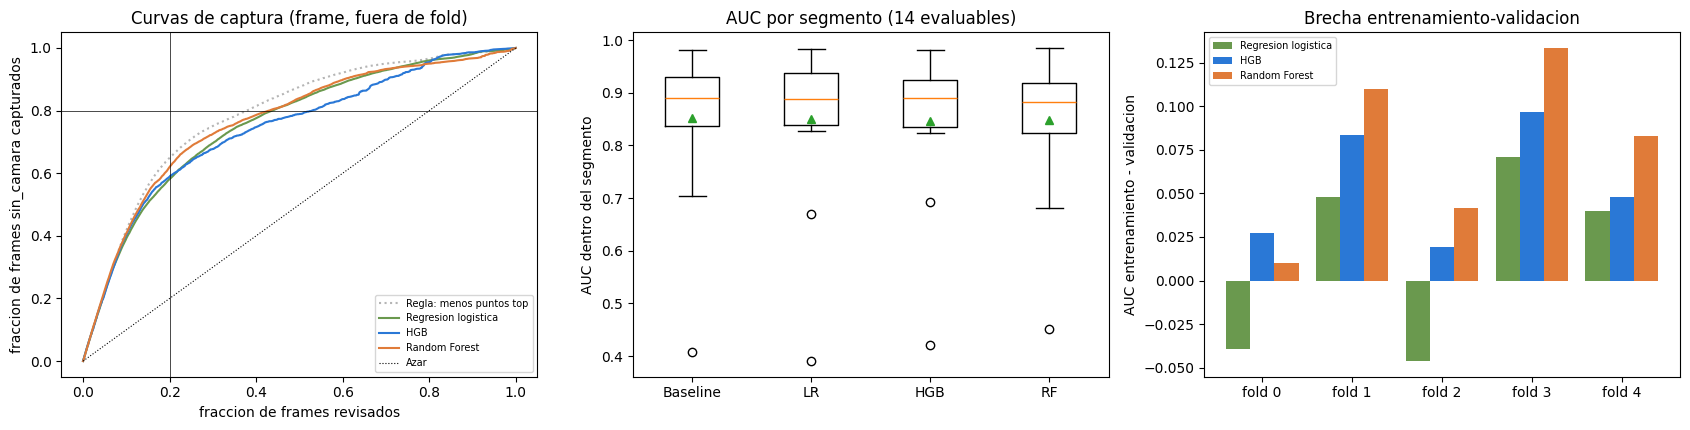

In [11]:
# ---- AUC por fold y por segmento; brecha entrenamiento-validacion
auc_fold = pd.DataFrame({n: [roc_auc_score(y[folds == k], s[folds == k]) for k in FOLDS] for n, s in scores_c.items() if n != "Prevalencia (trivial)"}, index=[f"fold {k}" for k in FOLDS])
print("AUC por fold:")
print(auc_fold.round(3).to_string())
seg_res, ev_res = {}, {}
for n, s in scores_c.items():
    if n == "Prevalencia (trivial)":
        continue
    t, ev, minimo = por_segmento_auc(s)
    seg_res[n], ev_res[n] = t, ev
res_seg = pd.DataFrame({n: {"mediana": e["auc"].median(), "Q1": e["auc"].quantile(0.25), "Q3": e["auc"].quantile(0.75), "min": e["auc"].min(), "max": e["auc"].max(), "segmentos": len(e)} for n, e in ev_res.items()}).T
print(f"\nAUC por segmento (segmentos con >= {minimo} filas por clase):")
print(res_seg.round(3).to_string())
brecha = pd.DataFrame({n: [roc_auc_score(y[folds != k], busq[m][k]["train_pred"]) - roc_auc_score(y[folds == k], busq[m][k]["val_pred"]) for k in FOLDS]
                       for n, m in [(NOMBRE_MOD[m_], m_) for m_ in MODELOS]}, index=[f"fold {k}" for k in FOLDS])
print("\nBrecha de AUC entrenamiento menos validacion (sobreajuste):")
print(brecha.round(3).to_string())
auc_fold.to_csv(RUTA_REPORTING / "09_auc_por_fold.csv"); res_seg.to_csv(RUTA_REPORTING / "09_auc_por_segmento.csv")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
estilos = {REGLA: (GRIS, "--"), "Regla: menos puntos top": ("#b5b5b5", ":"), "Regresion logistica": (VERDE, "-"), "HGB": (AZUL, "-"), "Random Forest": (NARANJA, "-")}
estilos = {k_: v_ for k_, v_ in estilos.items() if k_ in scores_c}
for n, (col, ls) in estilos.items():
    cum = curva_cap(y.astype(float), scores_c[n], tb_f)
    x = np.arange(1, len(cum) + 1) / len(cum)
    axes[0].plot(x[::50], cum[::50], color=col, ls=ls, label=n)
axes[0].plot([0, 1], [0, 1], color="k", lw=0.8, ls=":", label="Azar"); axes[0].axhline(0.8, color="k", lw=0.5); axes[0].axvline(0.2, color="k", lw=0.5)
axes[0].set_xlabel("fraccion de frames revisados"); axes[0].set_ylabel("fraccion de frames sin_camara capturados"); axes[0].set_title("Curvas de captura (frame, fuera de fold)"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].boxplot([ev_res[n]["auc"].dropna().values for n in [REGLA] + MODS], tick_labels=["Baseline"] + [{"Regresion logistica": "LR", "HGB": "HGB", "Random Forest": "RF"}[n] for n in MODS], showmeans=True)
axes[1].set_ylabel("AUC dentro del segmento"); axes[1].set_title(f"AUC por segmento ({len(ev_res['HGB'])} evaluables)")
w = 0.27
for i, n in enumerate(MODS):
    axes[2].bar(np.arange(len(FOLDS)) + (i - (len(MODS) - 1) / 2) * w, brecha[n].values, w, color={"Regresion logistica": VERDE, "HGB": AZUL, "Random Forest": NARANJA}[n], label=n)
axes[2].set_xticks(range(len(FOLDS)), [f"fold {k}" for k in FOLDS]); axes[2].set_ylabel("AUC entrenamiento - validacion"); axes[2].set_title("Brecha entrenamiento-validacion"); axes[2].legend(fontsize=7)
fig.tight_layout()
guardar_fig(fig, "09_comparacion_modelos")
plt.show()

In [12]:
# ---- Aplicacion de los criterios fijados antes
cr_v, cr_e, cr_s = CRIT["vale_la_pena"], CRIT["eleccion"], CRIT["estabilidad"]


def vale_la_pena(n):
    dA = delta(punto_c, boot_c, n, REGLA, "AUC")
    dF = delta(punto_c, boot_c, n, REGLA, "Fraccion para 80%")
    return bool(dF[0] <= cr_v["delta_fraccion80_max"] and dF[2] < 0 and dA[0] >= cr_v["delta_auc_min"]), dA, dF


def mejora_a_b(a, b):
    dA = delta(punto_c, boot_c, a, b, "AUC")
    dF = delta(punto_c, boot_c, a, b, "Fraccion para 80%")
    return bool(dA[0] >= cr_e["delta_auc_min"] and dA[1] > 0 and dF[0] < 0 and dF[2] < 0), dA, dF


vlp = {n: vale_la_pena(n) for n in MODS}
mejor_modelo = "Regresion logistica"
pasos = []
for cand in [c_ for c_ in ["HGB", "Random Forest"] if c_ in scores_c]:
    ok, dA, dF = mejora_a_b(cand, mejor_modelo)
    pasos.append((cand, mejor_modelo, ok, dA, dF))
    if ok:
        mejor_modelo = cand
recomendado = mejor_modelo
auc_min_fold = float(auc_fold[recomendado].min())
med_seg = float(res_seg.loc[recomendado, "mediana"])
estable = bool(auc_min_fold >= cr_s["auc_fold_min"] and med_seg >= cr_s["auc_segmento_mediana_min"])
CLAVE = {"Regresion logistica": "LR", "HGB": "HGB", "Random Forest": "RF"}
RES["C"] = {"recomendado": recomendado, "clave": CLAVE[recomendado], "vlp": {n: v[0] for n, v in vlp.items()}, "auc_min_fold": auc_min_fold, "mediana_segmento": med_seg, "estable": estable}

lineas = []
for n in MODS:
    ok, dA, dF = vlp[n]
    lineas.append(f"**{n}** frente al mejor baseline simple ({REGLA}): AUC {dA[0]:+.3f} (IC {dA[1]:+.3f} a {dA[2]:+.3f}) y Fracción para 80 % {dF[0] * 100:+.1f} puntos (IC {dF[1] * 100:+.1f} a {dF[2] * 100:+.1f}): " + ("**vale la pena** según el criterio." if ok else "**no cumple** el criterio de valer la pena (se pedía −5 puntos con IC que excluya 0 y +0,03 de AUC)."))
elec = []
for cand, base, ok, dA, dF in pasos:
    elec.append(f"{cand} frente a {base}: AUC {dA[0]:+.3f} (IC {dA[1]:+.3f} a {dA[2]:+.3f}), Fracción para 80 % {dF[0] * 100:+.1f} puntos (IC {dF[1] * 100:+.1f} a {dF[2] * 100:+.1f}) → " + ("pasa la prueba." if ok else "no pasa la prueba."))
display(Markdown(
    "**Conclusión (generada).** " + " ".join(lineas) + "\n\n**Elección del modelo.** " + " ".join(elec) + " " +
    (f"Ningún modelo supera a la regresión logística según el criterio: **se declaran equivalentes y se recomienda la regresión logística por interpretabilidad** (el HGB y el Random Forest quedan como comparación)." if recomendado == "Regresion logistica"
     else f"**Modelo recomendado: {recomendado}.**") +
    f"\n\n**Estabilidad del modelo recomendado ({recomendado}).** AUC mínimo por fold {n2(auc_min_fold, 3)} (umbral {cr_s['auc_fold_min']}) y mediana del AUC por segmento {n2(med_seg, 3)} (umbral {cr_s['auc_segmento_mediana_min']}): " + ("**cumple** ambos." if estable else "**no cumple** al menos uno.")))

**Conclusión (generada).** **Regresion logistica** frente al mejor baseline simple (Regla: menos puntos top): AUC -0.036 (IC -0.056 a -0.007) y Fracción para 80 % +5.8 puntos (IC -0.8 a +10.6): **no cumple** el criterio de valer la pena (se pedía −5 puntos con IC que excluya 0 y +0,03 de AUC). **HGB** frente al mejor baseline simple (Regla: menos puntos top): AUC -0.056 (IC -0.095 a -0.011) y Fracción para 80 % +15.1 puntos (IC +0.6 a +22.4): **no cumple** el criterio de valer la pena (se pedía −5 puntos con IC que excluya 0 y +0,03 de AUC). **Random Forest** frente al mejor baseline simple (Regla: menos puntos top): AUC -0.025 (IC -0.042 a -0.006) y Fracción para 80 % +5.1 puntos (IC -2.5 a +10.7): **no cumple** el criterio de valer la pena (se pedía −5 puntos con IC que excluya 0 y +0,03 de AUC).

**Elección del modelo.** HGB frente a Regresion logistica: AUC -0.020 (IC -0.052 a +0.012), Fracción para 80 % +9.3 puntos (IC -1.2 a +14.9) → no pasa la prueba. Random Forest frente a Regresion logistica: AUC +0.011 (IC -0.015 a +0.030), Fracción para 80 % -0.7 puntos (IC -6.7 a +5.0) → no pasa la prueba. Ningún modelo supera a la regresión logística según el criterio: **se declaran equivalentes y se recomienda la regresión logística por interpretabilidad** (el HGB y el Random Forest quedan como comparación).

**Estabilidad del modelo recomendado (Regresion logistica).** AUC mínimo por fold 0,811 (umbral 0.75) y mediana del AUC por segmento 0,888 (umbral 0.8): **cumple** ambos.

## C.2 Diagnóstico de la métrica agrupada (no cambia los criterios)

**Por qué importa.** El AUC agrupado mezcla las predicciones de **cinco modelos distintos** (uno por fold, con hiperparámetros distintos), mientras que la regla de puntos no tiene esa fuente de variación; además, cada fold tiene su propia escala de probabilidades.
Por eso se mira la diferencia modelo menos regla por fold, por segmento y con rangos percentiles dentro de cada fold. **Es un diagnóstico: el veredicto de los criterios fijados antes no cambia, solo se aclara su alcance.**

In [13]:
from scipy.stats import rankdata

REF_P = N_REGLA                                       # referencia pedida: regla de puntos
refs_d = [REF_P] + ([REGLA] if REGLA != REF_P else [])   # y el mejor baseline simple si es otro
DIAG = [N_REGLA, N_TOP, N_MIN] + MODS
seg_fold = pd.Series(df.groupby(seg_codes)["fold"].first().values).astype(int)
segs_k = {k: [idx_seg[s] for s in range(S_N) if seg_fold[s] == k and len(idx_seg[s])] for k in FOLDS}


def met_fold(sc, k):
    m = folds == k
    return metricas_score(y[m], sc[m], tb_f[m])


# ---- 1) por fold: metricas dentro de cada fold, promedio, y diferencias contra la referencia
pf = {n: pd.DataFrame([met_fold(scores_c[n], k) for k in FOLDS], index=FOLDS) for n in DIAG}
tabla_fold = pd.DataFrame({n: pf[n].mean() for n in DIAG}).T
print("Metricas calculadas dentro de cada fold y promediadas:")
print(tabla_fold.round(4).to_string())
# bootstrap pareado de segmentos, estratificado por fold (los segmentos se remuestrean dentro de su fold)
t0 = time.time()
rng = np.random.default_rng(SEMILLA)
acum = {n: {m: [] for m in MET} for n in DIAG}
for _ in range(200):
    por = {n: {m: [] for m in MET} for n in DIAG}
    for k in FOLDS:
        ss = segs_k[k]
        ii = np.concatenate([ss[j] for j in rng.integers(0, len(ss), len(ss))])
        if len(np.unique(y[ii])) < 2:
            continue
        for n in DIAG:
            r = metricas_score(y[ii], scores_c[n][ii], tb_f[ii])
            for m in MET:
                por[n][m].append(r[m])
    for n in DIAG:
        for m in MET:
            acum[n][m].append(np.mean(por[n][m]))
TIEMPOS["diagnostico_bootstrap_s"] = time.time() - t0
acum = {n: {m: np.array(v) for m, v in d.items()} for n, d in acum.items()}

filas, D1 = [], {}
for ref in refs_d:
    for n in [d_ for d_ in DIAG if d_ != ref]:
        for m in MET:
            dif_f = pf[n][m] - pf[ref][m]
            lo, hi = np.percentile(acum[n][m] - acum[ref][m], [2.5, 97.5])
            gana = int((dif_f > 0).sum()) if m in ("AUC", "PR-AUC", "Captura@20%") else int((dif_f < 0).sum())
            D1[(n, ref, m)] = {"media": float(dif_f.mean()), "min": float(dif_f.min()), "max": float(dif_f.max()), "gana": gana, "ic": (float(lo), float(hi))}
            filas.append({"modelo": n, "referencia": ref, "metrica": m, "dif media por fold": dif_f.mean(), "rango por fold": f"{dif_f.min():+.3f} a {dif_f.max():+.3f}", "folds donde el modelo supera": f"{gana} de {len(FOLDS)}", "IC95% (segmentos)": f"{lo:+.3f} a {hi:+.3f}"})
tabla_d1 = pd.DataFrame(filas)
print("\nDiferencias por fold (modelo menos referencia; en Fraccion para 80 % menos es mejor):")
print(tabla_d1[tabla_d1["metrica"].isin(["AUC", "Fraccion para 80%"])].round(4).to_string(index=False))

# ---- 2) por segmento: diferencia de AUC en los segmentos evaluables (los del 08)
def dif_seg(n, ref):
    a = ev_res[n].set_index("segmento")["auc"]
    return (a - ev_res[ref].set_index("segmento")["auc"].reindex(a.index)).dropna()

rng2 = np.random.default_rng(SEMILLA)
D2 = {}
for ref in refs_d:
    for n in [d_ for d_ in DIAG if d_ != ref]:
        d = dif_seg(n, ref)
        meds = np.array([np.median(rng2.choice(d.values, len(d), replace=True)) for _ in range(2000)])
        D2[(n, ref)] = {"mediana": float(d.median()), "q1": float(d.quantile(0.25)), "q3": float(d.quantile(0.75)), "prop": float((d > 0).mean()), "n": len(d), "ic": tuple(np.percentile(meds, [2.5, 97.5]))}
tabla_d2 = pd.DataFrame([{"modelo": n, "referencia": ref, "segmentos": v["n"], "mediana dif AUC": v["mediana"], "IQR": f"{v['q1']:+.3f} a {v['q3']:+.3f}", "proporcion donde el modelo supera": v["prop"],
                          "IC95% mediana": f"{v['ic'][0]:+.3f} a {v['ic'][1]:+.3f}"} for (n, ref), v in D2.items()])
print("\nDiferencia de AUC por segmento (modelo menos referencia, segmentos evaluables):")
print(tabla_d2.round(4).to_string(index=False))

# ---- 3) AUC agrupado con rangos percentiles dentro de cada fold (normaliza la escala de cada fold)
rk = {}
for n in DIAG:
    r_ = np.zeros(len(y))
    for k in FOLDS:
        m = folds == k
        r_[m] = rankdata(scores_c[n][m]) / m.sum()
    rk[n] = r_
auc_rk = {n: roc_auc_score(y, rk[n]) for n in DIAG}
print("\nAUC agrupado con rangos percentiles dentro de cada fold (diagnostico):", {n: round(v, 3) for n, v in auc_rk.items()})
pd.concat([tabla_d1.assign(parte="por fold"), tabla_d2.assign(parte="por segmento")], ignore_index=True).to_csv(RUTA_REPORTING / "09_diagnostico_agrupado.csv", index=False)


# ---- 4) parrafo y veredicto (solo aclara el alcance; los criterios fijados no cambian)
def veredicto(ic_f, ic_s):
    if ic_f[0] <= 0 <= ic_f[1] and ic_s[0] <= 0 <= ic_s[1]:
        return "el modelo no se distingue de la regla"
    if ic_f[1] < 0 and ic_s[1] < 0:
        return "el modelo es peor que la regla"
    if ic_f[0] > 0 and ic_s[0] > 0:
        return "el modelo es mejor que la regla"
    return "la evidencia es mixta (un IC incluye 0 y el otro no)"


lineas, RES["C2"] = [], {"veredictos": {}}
for ref in refs_d:
    for n in MODS:
        ag = punto_c[n]["AUC"] - punto_c[ref]["AUC"]
        a1, s1 = D1[(n, ref, "AUC")], D2[(n, ref)]
        f1 = D1[(n, ref, "Fraccion para 80%")]
        mucho = abs(ag) >= 2 * max(abs(a1["media"]), 1e-9)
        ver = veredicto(a1["ic"], s1["ic"])
        RES["C2"]["veredictos"][(n, ref)] = {"veredicto": ver, "agrupada": float(ag), "fold": a1["media"], "segmento": s1["mediana"], "mucho_mayor": bool(mucho)}
        lineas.append(f"**{n} menos {ref}:** diferencia de AUC agrupada {ag:+.3f}; por fold {a1['media']:+.3f} en promedio (rango {a1['min']:+.3f} a {a1['max']:+.3f}; supera en {a1['gana']} de {len(FOLDS)} folds; IC 95 % {a1['ic'][0]:+.3f} a {a1['ic'][1]:+.3f}); "
                       f"por segmento, mediana {s1['mediana']:+.3f} (IQR {s1['q1']:+.3f} a {s1['q3']:+.3f}; supera en el {pct(s1['prop'], 0)} de {s1['n']} segmentos; IC 95 % de la mediana {s1['ic'][0]:+.3f} a {s1['ic'][1]:+.3f}); "
                       f"Fracción para 80 % por fold {f1['media'] * 100:+.1f} puntos (IC {f1['ic'][0] * 100:+.1f} a {f1['ic'][1] * 100:+.1f}); con rangos percentiles por fold, {auc_rk[n] - auc_rk[ref]:+.3f}. "
                       f"La brecha agrupada es {'**mucho mayor que**' if mucho else 'del mismo orden que'} la brecha por fold. Lectura: **{ver}**.")
no_dist = [n for n in MODS if RES["C2"]["veredictos"][(n, REF_P)]["veredicto"] == "el modelo no se distingue de la regla"]
RES["C2"]["no_dist"] = no_dist
vlp_txt = ", ".join(f"{n}: {'vale la pena' if v[0] else 'no vale la pena'}" for n, v in vlp.items())
muchos = all(v["mucho_mayor"] for (n_, r_), v in RES["C2"]["veredictos"].items() if r_ == REF_P)
ver_base = {n: RES["C2"]["veredictos"][(n, REGLA)]["veredicto"] for n in MODS}
RES["C2"]["resumen"] = ("Diagnóstico (C.2): " + ("la brecha agrupada de AUC entre modelo y regla de puntos es mucho mayor que la brecha por fold y por segmento" if muchos else "las brechas agrupada, por fold y por segmento son del mismo orden") +
                        ("; por fold y por segmento los IC incluyen 0 para " + ", ".join(no_dist) + ", así que **el modelo no se distingue de la regla de puntos**" if no_dist else "; ningún modelo tiene ambos IC incluyendo 0 frente a la regla de puntos") +
                        f". Frente al mejor baseline simple ({REGLA}): " + "; ".join(f"{n}: {v}" for n, v in ver_base.items()) +
                        f". El veredicto de los criterios fijados antes (frente al mejor baseline simple: {vlp_txt}) no cambia: lo que cambia es su alcance, porque «no vale la pena» no equivale a «es peor».")
display(Markdown("**Lectura (generada).** " + "\n\n".join(lineas) + "\n\n" + RES["C2"]["resumen"]))

Metricas calculadas dentro de cada fold y promediadas:
                                   AUC  PR-AUC  Captura@20%  Fraccion para 80%
Regla: menos puntos LiDAR       0.8604  0.7157       0.6578             0.3810
Regla: menos puntos top         0.8627  0.7211       0.6603             0.3780
Modelo minimo (LR 3 variables)  0.8626  0.7326       0.6624             0.3685
Regresion logistica             0.8585  0.7190       0.6514             0.3632
HGB                             0.8572  0.7256       0.6464             0.3900
Random Forest                   0.8563  0.7308       0.6490             0.3817



Diferencias por fold (modelo menos referencia; en Fraccion para 80 % menos es mejor):
                        modelo                referencia           metrica  dif media por fold  rango por fold folds donde el modelo supera IC95% (segmentos)
       Regla: menos puntos top Regla: menos puntos LiDAR               AUC              0.0023 +0.001 a +0.007                       5 de 5   +0.001 a +0.006
       Regla: menos puntos top Regla: menos puntos LiDAR Fraccion para 80%             -0.0031 -0.008 a -0.001                       5 de 5   -0.010 a +0.000
Modelo minimo (LR 3 variables) Regla: menos puntos LiDAR               AUC              0.0022 -0.010 a +0.009                       3 de 5   -0.001 a +0.009
Modelo minimo (LR 3 variables) Regla: menos puntos LiDAR Fraccion para 80%             -0.0126 -0.021 a -0.002                       5 de 5   -0.025 a +0.006
           Regresion logistica Regla: menos puntos LiDAR               AUC             -0.0019 -0.009 a +0.012             


Diferencia de AUC por segmento (modelo menos referencia, segmentos evaluables):
                        modelo                referencia  segmentos  mediana dif AUC             IQR  proporcion donde el modelo supera   IC95% mediana
       Regla: menos puntos top Regla: menos puntos LiDAR         14           0.0009 +0.000 a +0.002                             0.9286 +0.000 a +0.002
Modelo minimo (LR 3 variables) Regla: menos puntos LiDAR         14           0.0037 -0.003 a +0.012                             0.6429 -0.003 a +0.013
           Regresion logistica Regla: menos puntos LiDAR         14           0.0000 -0.007 a +0.006                             0.5000 -0.008 a +0.007
                           HGB Regla: menos puntos LiDAR         14          -0.0078 -0.011 a +0.007                             0.2857 -0.011 a +0.011
                 Random Forest Regla: menos puntos LiDAR         14          -0.0096 -0.018 a +0.014                             0.4286 -0.016 a +0.013
     Re

**Lectura (generada).** **Regresion logistica menos Regla: menos puntos LiDAR:** diferencia de AUC agrupada -0.033; por fold -0.002 en promedio (rango -0.009 a +0.012; supera en 1 de 5 folds; IC 95 % -0.008 a +0.036); por segmento, mediana +0.000 (IQR -0.007 a +0.006; supera en el 50 % de 14 segmentos; IC 95 % de la mediana -0.008 a +0.007); Fracción para 80 % por fold -1.8 puntos (IC -8.4 a +1.1); con rangos percentiles por fold, -0.001. La brecha agrupada es **mucho mayor que** la brecha por fold. Lectura: **el modelo no se distingue de la regla**.

**HGB menos Regla: menos puntos LiDAR:** diferencia de AUC agrupada -0.053; por fold -0.003 en promedio (rango -0.006 a +0.000; supera en 1 de 5 folds; IC 95 % -0.010 a +0.024); por segmento, mediana -0.008 (IQR -0.011 a +0.007; supera en el 29 % de 14 segmentos; IC 95 % de la mediana -0.011 a +0.011); Fracción para 80 % por fold +0.9 puntos (IC -5.3 a +3.0); con rangos percentiles por fold, -0.003. La brecha agrupada es **mucho mayor que** la brecha por fold. Lectura: **el modelo no se distingue de la regla**.

**Random Forest menos Regla: menos puntos LiDAR:** diferencia de AUC agrupada -0.022; por fold -0.004 en promedio (rango -0.024 a +0.009; supera en 3 de 5 folds; IC 95 % -0.011 a +0.017); por segmento, mediana -0.010 (IQR -0.018 a +0.014; supera en el 43 % de 14 segmentos; IC 95 % de la mediana -0.016 a +0.013); Fracción para 80 % por fold +0.1 puntos (IC -4.5 a +2.3); con rangos percentiles por fold, -0.006. La brecha agrupada es **mucho mayor que** la brecha por fold. Lectura: **el modelo no se distingue de la regla**.

**Regresion logistica menos Regla: menos puntos top:** diferencia de AUC agrupada -0.036; por fold -0.004 en promedio (rango -0.010 a +0.005; supera en 1 de 5 folds; IC 95 % -0.010 a +0.033); por segmento, mediana -0.001 (IQR -0.008 a +0.002; supera en el 43 % de 14 segmentos; IC 95 % de la mediana -0.008 a +0.002); Fracción para 80 % por fold -1.5 puntos (IC -8.1 a +1.3); con rangos percentiles por fold, -0.003. La brecha agrupada es **mucho mayor que** la brecha por fold. Lectura: **el modelo no se distingue de la regla**.

**HGB menos Regla: menos puntos top:** diferencia de AUC agrupada -0.056; por fold -0.006 en promedio (rango -0.011 a -0.000; supera en 0 de 5 folds; IC 95 % -0.012 a +0.021); por segmento, mediana -0.009 (IQR -0.013 a -0.001; supera en el 21 % de 14 segmentos; IC 95 % de la mediana -0.013 a -0.001); Fracción para 80 % por fold +1.2 puntos (IC -4.9 a +3.4); con rangos percentiles por fold, -0.006. La brecha agrupada es **mucho mayor que** la brecha por fold. Lectura: **la evidencia es mixta (un IC incluye 0 y el otro no)**.

**Random Forest menos Regla: menos puntos top:** diferencia de AUC agrupada -0.025; por fold -0.006 en promedio (rango -0.025 a +0.009; supera en 1 de 5 folds; IC 95 % -0.012 a +0.013); por segmento, mediana -0.010 (IQR -0.020 a +0.004; supera en el 43 % de 14 segmentos; IC 95 % de la mediana -0.021 a +0.005); Fracción para 80 % por fold +0.4 puntos (IC -4.2 a +2.5); con rangos percentiles por fold, -0.009. La brecha agrupada es **mucho mayor que** la brecha por fold. Lectura: **el modelo no se distingue de la regla**.

Diagnóstico (C.2): la brecha agrupada de AUC entre modelo y regla de puntos es mucho mayor que la brecha por fold y por segmento; por fold y por segmento los IC incluyen 0 para Regresion logistica, HGB, Random Forest, así que **el modelo no se distingue de la regla de puntos**. Frente al mejor baseline simple (Regla: menos puntos top): Regresion logistica: el modelo no se distingue de la regla; HGB: la evidencia es mixta (un IC incluye 0 y el otro no); Random Forest: el modelo no se distingue de la regla. El veredicto de los criterios fijados antes (frente al mejor baseline simple: Regresion logistica: no vale la pena, HGB: no vale la pena, Random Forest: no vale la pena) no cambia: lo que cambia es su alcance, porque «no vale la pena» no equivale a «es peor».

# D. Puntos de operación

**Por qué importa.** Un modelo de ranking no decide por sí solo qué revisar: hace falta un corte. Aquí se fijan cortes **con los datos de entrenamiento de cada fold** (predicciones internas fuera de fold) y se miden en el fold que no se usó para elegirlos. Punto A: recall objetivo 0,80. Punto B: presupuesto de revisión del 20 %. Referencia: máximo F1.

In [14]:
cr_o = CRIT["operacion"]


def umbral_recall(score_tr, y_tr, recall_obj):
    o = np.argsort(-score_tr, kind="stable")
    rec = np.cumsum(y_tr[o]) / y_tr.sum()
    return score_tr[o][int(np.searchsorted(rec, recall_obj))]


def umbral_f1(score_tr, y_tr):
    o = np.argsort(-score_tr, kind="stable")
    ys = y_tr[o]
    tp = np.cumsum(ys)
    prec, rec = tp / np.arange(1, len(ys) + 1), tp / ys.sum()
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return score_tr[o][int(np.argmax(f1))]


def umbrales_fold(metodo, k):
    tr = folds != k
    if metodo == "Regla":
        s_tr = BASE_TR(k)
    else:
        s_tr = busq[metodo][k]["inner_oof"]
    return {"A": umbral_recall(s_tr, y[tr], cr_o["recall_objetivo"]), "B": float(np.quantile(s_tr, 1 - cr_o["presupuesto_revision"])), "F1": umbral_f1(s_tr, y[tr])}


def marcar(metodo):
    sc = {"Regla": s_base, **{m: oof[m] for m in MODELOS}}[metodo]
    banderas = {p: np.zeros(len(y), bool) for p in ("A", "B", "F1")}
    thr = {p: [] for p in banderas}
    for k in FOLDS:
        u = umbrales_fold(metodo, k)
        va = folds == k
        for p in banderas:
            banderas[p][va] = sc[va] >= u[p]
            thr[p].append(float(u[p]))
    return banderas, thr


def metricas_flags(flag, yy):
    tp, fp, fn, tn = int((flag & (yy == 1)).sum()), int((flag & (yy == 0)).sum()), int((~flag & (yy == 1)).sum()), int((~flag & (yy == 0)).sum())
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precision": p, "recall": r, "F1": 2 * p * r / max(p + r, 1e-12), "pct_revisar": (tp + fp) / len(yy)}


def boot_flags(flag, n_boot=300, seed=SEMILLA):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        ii = np.concatenate([idx_seg[j] for j in rng.integers(0, S_N, S_N)])
        out.append(metricas_flags(flag[ii], y[ii]))
    return pd.DataFrame(out)


BANDERAS, UMBRALES = {}, {}
for metodo in ["Regla"] + MODELOS:
    BANDERAS[metodo], UMBRALES[metodo] = marcar(metodo)
NOMBRE = {"Regla": REGLA, "LR": "Regresion logistica", "HGB": "HGB", "RF": "Random Forest"}
filas, boots = [], {}
for metodo in ["Regla"] + MODELOS:
    for p, desc in [("A", "A: recall objetivo 0,80"), ("B", "B: revisar 20 %"), ("F1", "referencia: maximo F1")]:
        m = metricas_flags(BANDERAS[metodo][p], y)
        b = boot_flags(BANDERAS[metodo][p]) if metodo in ("Regla", RES["C"]["clave"], "LR") else None
        boots[(metodo, p)] = b
        fila = {"metodo": NOMBRE[metodo], "punto": desc, "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "TN": m["TN"]}
        for kk in ("recall", "precision", "F1", "pct_revisar"):
            fila[kk] = f"{m[kk]:.3f}" + (f" ({np.percentile(b[kk], 2.5):.3f} a {np.percentile(b[kk], 97.5):.3f})" if b is not None else "")
        filas.append(fila)
tabla_d = pd.DataFrame(filas)
print(tabla_d.to_string(index=False))
tabla_d.to_csv(RUTA_REPORTING / "09_puntos_operacion.csv", index=False)
print("\nUmbrales de probabilidad por fold (A):", {NOMBRE[m]: [round(v, 3) for v in UMBRALES[m]["A"]] for m in MODELOS})

                 metodo                   punto    TP    FP   FN    TN                recall             precision                    F1           pct_revisar
Regla: menos puntos top A: recall objetivo 0,80 10774 13660 2594 37481 0.806 (0.760 a 0.869) 0.441 (0.346 a 0.519) 0.570 (0.483 a 0.637) 0.379 (0.340 a 0.422)
Regla: menos puntos top         B: revisar 20 %  8896  4666 4472 46475 0.665 (0.602 a 0.745) 0.656 (0.510 a 0.744) 0.661 (0.578 a 0.730) 0.210 (0.182 a 0.244)
Regla: menos puntos top   referencia: maximo F1  8506  4213 4862 46928 0.636 (0.563 a 0.726) 0.669 (0.523 a 0.764) 0.652 (0.570 a 0.722) 0.197 (0.175 a 0.225)
    Regresion logistica A: recall objetivo 0,80 10830 14269 2538 36872 0.810 (0.761 a 0.874) 0.431 (0.339 a 0.516) 0.563 (0.477 a 0.630) 0.389 (0.352 a 0.438)
    Regresion logistica         B: revisar 20 %  8607  4553 4761 46588 0.644 (0.569 a 0.741) 0.654 (0.511 a 0.749) 0.649 (0.568 a 0.726) 0.204 (0.177 a 0.234)
    Regresion logistica   referencia: maximo F

In [15]:
# ---- Por fold, por segmento, y horas ilustrativas
clave = RES["C"]["clave"]
sc_rec = oof[clave]
filas = []
for k in FOLDS:
    va = folds == k
    for p in ("A", "B", "F1"):
        m = metricas_flags(BANDERAS[clave][p][va], y[va])
        filas.append({"fold": k, "punto": p, "recall": m["recall"], "precision": m["precision"], "pct_revisar": m["pct_revisar"]})
por_fold_d = pd.DataFrame(filas)
print(f"Por fold ({NOMBRE[clave]}):")
print(por_fold_d.pivot(index="fold", columns="punto", values=["recall", "precision", "pct_revisar"]).round(3).to_string())

segd = []
for si in range(S_N):
    ii = idx_seg[si]
    npos = int(y[ii].sum())
    m = metricas_flags(BANDERAS[clave]["A"][ii], y[ii])
    segd.append({"segmento": seg_nombres[si], "filas": len(ii), "positivos": npos, "recall_A": m["recall"] if npos else np.nan, "pct_revisar_A": m["pct_revisar"]})
segd = pd.DataFrame(segd)
evald = segd[segd["positivos"] >= cr_o["min_positivos_segmento"]]
n_ok = int((evald["recall_A"] >= cr_o["recall_segmento_min"]).sum())
print(f"\nSegmentos con >= {cr_o['min_positivos_segmento']} frames sin_camara: {len(evald)} de {len(segd)}; con recall >= {cr_o['recall_segmento_min']} al punto A: {n_ok}")
segd.to_csv(RUTA_REPORTING / "09_recall_por_segmento.csv", index=False)

# horas ilustrativas (supuesto de segundos por revision, igual al 07; no es un dato medido)
SEGUNDOS_POR_REVISION = 20
mA = metricas_flags(BANDERAS[clave]["A"], y)
mR = metricas_flags(BANDERAS["Regla"]["A"], y)
horas_total = len(y) * SEGUNDOS_POR_REVISION / 3600
cum_regla = curva_cap(y.astype(float), s_base, tb_f)
frac_regla_mismo_recall = (np.searchsorted(cum_regla, mA["recall"]) + 1) / len(cum_regla)
h_modelo, h_azar, h_regla = horas_total * mA["pct_revisar"], horas_total * mA["recall"], horas_total * frac_regla_mismo_recall
RES["D"] = {"A": mA, "A_regla": mR, "ic": {kk: (np.percentile(boots[(clave, "A")][kk], 2.5), np.percentile(boots[(clave, "A")][kk], 97.5)) for kk in ("recall", "precision", "pct_revisar")},
            "n_ok": n_ok, "n_eval": len(evald), "horas": {"total": horas_total, "modelo": h_modelo, "azar": h_azar, "regla": h_regla, "seg": SEGUNDOS_POR_REVISION}, "B": metricas_flags(BANDERAS[clave]["B"], y), "F1": metricas_flags(BANDERAS[clave]["F1"], y)}
d = RES["D"]
display(Markdown(
    f"**Lectura (generada, {NOMBRE[clave]}).** **Punto A** (umbral con datos de entrenamiento apuntando a recall 0,80): recall alcanzado {n2(d['A']['recall'], 3)} (IC 95 % {n2(d['ic']['recall'][0], 3)} a {n2(d['ic']['recall'][1], 3)}), precisión {n2(d['A']['precision'], 3)} "
    f"(IC {n2(d['ic']['precision'][0], 3)} a {n2(d['ic']['precision'][1], 3)}) y {pct(d['A']['pct_revisar'])} de los frames a revisar (IC {pct(d['ic']['pct_revisar'][0])} a {pct(d['ic']['pct_revisar'][1])}). "
    f"**Punto B** (corte en el percentil 80 de las predicciones internas): recall {n2(d['B']['recall'], 3)}, precisión {n2(d['B']['precision'], 3)}, {pct(d['B']['pct_revisar'])} revisado. "
    f"**Referencia de máximo F1:** F1 {n2(d['F1']['F1'], 3)}, recall {n2(d['F1']['recall'], 3)}, precisión {n2(d['F1']['precision'], 3)}, {pct(d['F1']['pct_revisar'])} revisado. "
    f"El mejor baseline simple ({REGLA}), con el mismo método de umbral, logra recall {n2(d['A_regla']['recall'], 3)} revisando el {pct(d['A_regla']['pct_revisar'])}. "
    f"Por segmento, {d['n_ok']} de {d['n_eval']} segmentos evaluables (≥ {cr_o['min_positivos_segmento']} frames `sin_camara`) alcanzan recall ≥ {cr_o['recall_segmento_min']} al punto A.\n\n"
    f"**Horas, solo como ilustración con el supuesto de {d['horas']['seg']} s por revisión (no es un dato medido):** revisar todo costaría {miles(d['horas']['total'])} h; al punto A el modelo cuesta {miles(d['horas']['modelo'])} h, "
    f"el mejor baseline simple ({REGLA}) necesitaría {miles(d['horas']['regla'])} h para el mismo recall y el azar {miles(d['horas']['azar'])} h; el ahorro es de {miles(d['horas']['regla'] - d['horas']['modelo'])} h frente al baseline y de {miles(d['horas']['azar'] - d['horas']['modelo'])} h frente al azar."))

Por fold (Regresion logistica):
      recall               precision               pct_revisar              
punto      A      B     F1         A      B     F1           A      B     F1
fold                                                                        
0      0.924  0.722  0.675     0.405  0.656  0.671       0.454  0.219  0.201
1      0.798  0.707  0.725     0.422  0.765  0.704       0.318  0.155  0.173
2      0.829  0.619  0.554     0.616  0.833  0.867       0.386  0.213  0.183
3      0.744  0.569  0.577     0.384  0.598  0.591       0.336  0.165  0.169
4      0.805  0.687  0.673     0.335  0.511  0.537       0.462  0.258  0.241

Segmentos con >= 50 frames sin_camara: 22 de 33; con recall >= 0.75 al punto A: 16


**Lectura (generada, Regresion logistica).** **Punto A** (umbral con datos de entrenamiento apuntando a recall 0,80): recall alcanzado 0,810 (IC 95 % 0,761 a 0,874), precisión 0,431 (IC 0,339 a 0,516) y 38,9 % de los frames a revisar (IC 35,2 % a 43,8 %). **Punto B** (corte en el percentil 80 de las predicciones internas): recall 0,644, precisión 0,654, 20,4 % revisado. **Referencia de máximo F1:** F1 0,638, recall 0,618, precisión 0,659, 19,4 % revisado. El mejor baseline simple (Regla: menos puntos top), con el mismo método de umbral, logra recall 0,806 revisando el 37,9 %. Por segmento, 16 de 22 segmentos evaluables (≥ 50 frames `sin_camara`) alcanzan recall ≥ 0.75 al punto A.

**Horas, solo como ilustración con el supuesto de 20 s por revisión (no es un dato medido):** revisar todo costaría 358 h; al punto A el modelo cuesta 139 h, el mejor baseline simple (Regla: menos puntos top) necesitaría 140 h para el mismo recall y el azar 290 h; el ahorro es de 1 h frente al baseline y de 150 h frente al azar.

# E. Calibración y modelos finales

**Por qué importa.** Si se van a publicar probabilidades (por ejemplo "esta caja tiene 40 % de probabilidad de no tener par 2D"), tienen que significar lo que dicen. Se mide la calibración del modelo recomendado crudo y con Platt e isotónica, ajustadas **dentro de cada fold** con las predicciones internas de los segmentos de entrenamiento. El ECE usa 10 bins por cuantiles.

## E.1 Calibración del modelo recomendado

Calibracion del modelo recomendado (Regresion logistica):
              ECE   Brier     AUC  probabilidad media  prevalencia
version                                                           
Crudo      0.0443  0.1152  0.8253              0.2470       0.2072
Platt      0.0128  0.1038  0.8496              0.2099       0.2072
Isotonica  0.0296  0.1050  0.8405              0.2108       0.2072



Contexto (modelos crudos):
                     ECE crudo  Brier crudo  probabilidad media
Regresion logistica     0.0443       0.1152              0.2470
HGB                     0.0838       0.1230              0.2833
Random Forest           0.0214       0.1044              0.2113


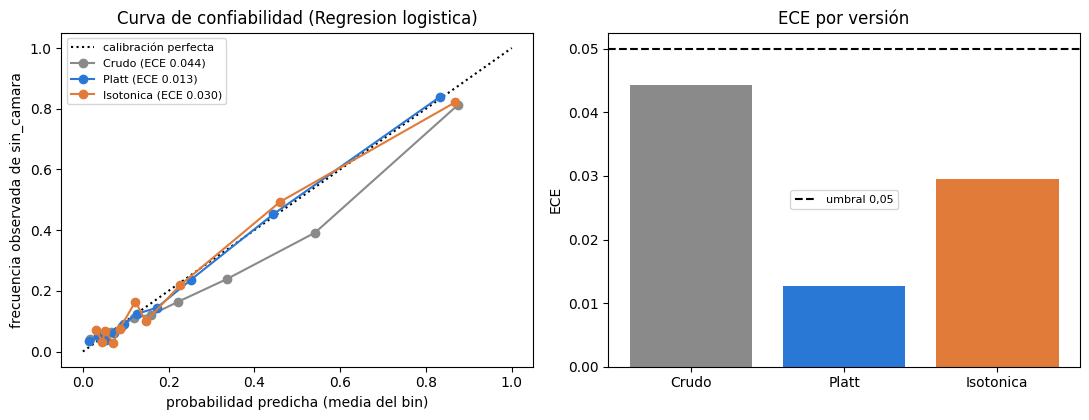

**Lectura (generada).** El modelo recomendado (Regresion logistica) crudo tiene ECE 0,044 y Brier 0,1152, con probabilidad media predicha 0,247 frente a una prevalencia de 0,207. Con Platt el ECE es 0,013 y con isotónica 0,030. El mejor es **Platt** (Brier 0,1038). Criterio (ECE ≤ 0.05 tras calibrar): **se cumple**. Si se publican probabilidades, conviene usar la versión calibrada; **ojo con el AUC agrupado:** pasa de 0,825 (crudo) a 0,850 (Platt) y 0,841 (isotónica), pero el AUC promedio por fold es 0,859 crudo, 0,859 con Platt y 0,857 con isotónica. La calibración por fold no mejora el ranking dentro de cada fold: **alinea la escala de las probabilidades entre folds** (cada fold tiene su propio modelo), y eso sube el AUC agrupado. La calibración importa para interpretar el valor de la probabilidad y para fijar umbrales de probabilidad.

In [16]:
def ece_cuantiles(yv, pv, n_bins=10):
    b = pd.qcut(pd.Series(pv).rank(method="first"), n_bins, labels=False)
    g = pd.DataFrame({"y": yv, "p": pv, "b": b.values}).groupby("b").agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    return float((g["n"] / g["n"].sum() * (g["obs"] - g["pred"]).abs()).sum()), g


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


clave = RES["C"]["clave"]
recomendado = RES["C"]["recomendado"]
cal = {"Crudo": np.zeros(len(y)), "Platt": np.zeros(len(y)), "Isotonica": np.zeros(len(y))}
for k in FOLDS:
    tr, va = folds != k, folds == k
    p_in, p_va = busq[clave][k]["inner_oof"], busq[clave][k]["val_pred"]
    cal["Crudo"][va] = p_va
    cal["Platt"][va] = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_in), y[tr]).predict_proba(logit(p_va))[:, 1]
    cal["Isotonica"][va] = IsotonicRegression(out_of_bounds="clip").fit(p_in, y[tr]).predict(p_va)
filas, curvas = [], {}
for n, p in cal.items():
    e, g = ece_cuantiles(y, p)
    curvas[n] = g
    filas.append({"version": n, "ECE": e, "Brier": brier_score_loss(y, p), "AUC": roc_auc_score(y, p), "probabilidad media": p.mean(), "prevalencia": y.mean()})
tabla_cal = pd.DataFrame(filas).set_index("version")
print(f"Calibracion del modelo recomendado ({recomendado}):")
print(tabla_cal.round(4).to_string())
# contexto: ECE y Brier crudos de los tres modelos
ctx = pd.DataFrame({NOMBRE[m]: {"ECE crudo": ece_cuantiles(y, oof[m])[0], "Brier crudo": brier_score_loss(y, oof[m]), "probabilidad media": oof[m].mean()} for m in MODELOS}).T
print("\nContexto (modelos crudos):")
print(ctx.round(4).to_string())
tabla_cal.to_csv(RUTA_REPORTING / "09_calibracion.csv")
mejor_cal = tabla_cal["ECE"].idxmin()
ece_post = float(tabla_cal.loc[[v for v in ("Platt", "Isotonica")], "ECE"].min())
cal_ok = bool(ece_post <= CRIT["calibracion"]["ece_max"])
RES["E"] = {"ece_crudo": float(tabla_cal.loc["Crudo", "ECE"]), "ece_platt": float(tabla_cal.loc["Platt", "ECE"]), "ece_iso": float(tabla_cal.loc["Isotonica", "ECE"]), "brier_crudo": float(tabla_cal.loc["Crudo", "Brier"]),
            "brier_mejor": float(tabla_cal.loc[mejor_cal, "Brier"]), "mejor": mejor_cal, "ok": cal_ok, "prob_media_cruda": float(tabla_cal.loc["Crudo", "probabilidad media"])}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].plot([0, 1], [0, 1], color="k", ls=":", label="calibración perfecta")
for n, col in [("Crudo", GRIS), ("Platt", AZUL), ("Isotonica", NARANJA)]:
    g = curvas[n]
    axes[0].plot(g["pred"], g["obs"], marker="o", color=col, label=f"{n} (ECE {tabla_cal.loc[n, 'ECE']:.3f})")
axes[0].set_xlabel("probabilidad predicha (media del bin)"); axes[0].set_ylabel("frecuencia observada de sin_camara"); axes[0].set_title(f"Curva de confiabilidad ({recomendado})"); axes[0].legend(fontsize=8)
axes[1].bar(range(3), [tabla_cal.loc[n, "ECE"] for n in cal], color=[GRIS, AZUL, NARANJA]); axes[1].axhline(CRIT["calibracion"]["ece_max"], color="k", ls="--", label="umbral 0,05")
axes[1].set_xticks(range(3), list(cal)); axes[1].set_ylabel("ECE"); axes[1].set_title("ECE por versión"); axes[1].legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "09_calibracion")
plt.show()
auc_agr = {n: float(tabla_cal.loc[n, "AUC"]) for n in tabla_cal.index}
auc_fold_cal = {n: float(np.mean([roc_auc_score(y[folds == k], cal[n][folds == k]) for k in FOLDS])) for n in cal}
r = RES["E"]
display(Markdown(
    f"**Lectura (generada).** El modelo recomendado ({recomendado}) crudo tiene ECE {n2(r['ece_crudo'], 3)} y Brier {n2(r['brier_crudo'], 4)}, con probabilidad media predicha {n2(r['prob_media_cruda'], 3)} frente a una prevalencia de {n2(y.mean(), 3)}. "
    f"Con Platt el ECE es {n2(r['ece_platt'], 3)} y con isotónica {n2(r['ece_iso'], 3)}. El mejor es **{r['mejor']}** (Brier {n2(r['brier_mejor'], 4)}). Criterio (ECE ≤ {CRIT['calibracion']['ece_max']} tras calibrar): " +
    ("**se cumple**." if r["ok"] else "**no se cumple**.") +
    (" Si se publican probabilidades, conviene usar la versión calibrada" if r["mejor"] != "Crudo" else " La versión cruda ya es la mejor calibrada") +
    f"; **ojo con el AUC agrupado:** pasa de {n2(auc_agr['Crudo'], 3)} (crudo) a {n2(auc_agr['Platt'], 3)} (Platt) y {n2(auc_agr['Isotonica'], 3)} (isotónica), pero el AUC promedio por fold es {n2(auc_fold_cal['Crudo'], 3)} crudo, {n2(auc_fold_cal['Platt'], 3)} con Platt y {n2(auc_fold_cal['Isotonica'], 3)} con isotónica. "
    f"La calibración por fold no mejora el ranking dentro de cada fold: **alinea la escala de las probabilidades entre folds** (cada fold tiene su propio modelo), y eso sube el AUC agrupado. La calibración importa para interpretar el valor de la probabilidad y para fijar umbrales de probabilidad."))

## E.2 Modelos finales sobre todo train (insumo del 10)

Con la misma búsqueda (validación interna agrupada por segmento) pero sobre **todos** los segmentos de train se elige la configuración final, se ajusta el modelo y se fijan los umbrales A, B y F1 con las predicciones internas fuera de fold de todo train. **No se evalúan en test.**

In [17]:
RUTA_CACHE_F = RUTA_SALIDA / "_cache_09_final.joblib"
final = None
if USAR_CACHE and RUTA_CACHE_F.exists():
    c = joblib.load(RUTA_CACHE_F)
    if c.get("firma") == firma:
        final = {n: {**d, "modelo": crear(n, d["cfg"]).fit(X, y)} for n, d in c["final"].items()}
        print("Se reutiliza la cache del ajuste final (los modelos se vuelven a ajustar sobre todo train).")
if final is None:
    t0 = time.time()
    final = {}
    for nombre in MODELOS:
        cfg, sc, tabla = buscar(nombre, X, y, grupos)
        inner = oof_interno(nombre, cfg, X, y, grupos)
        final[nombre] = {"cfg": cfg, "score_interno": sc, "n_evaluadas": len(tabla), "inner_oof": inner, "modelo": crear(nombre, cfg).fit(X, y)}
        print(f"  {nombre}: {len(tabla)} configuraciones | PR-AUC interno {sc:.3f} | {cfg} | {time.time() - t0:.0f} s acumulados")
    TIEMPOS["ajuste_final_s"] = time.time() - t0
    joblib.dump({"firma": firma, "final": {n: {kk: vv for kk, vv in d.items() if kk != "modelo"} for n, d in final.items()}}, RUTA_CACHE_F)
for nombre in MODELOS:
    inner = final[nombre]["inner_oof"]
    final[nombre]["umbrales"] = {"A": float(umbral_recall(inner, y, CRIT["operacion"]["recall_objetivo"])), "B": float(np.quantile(inner, 1 - CRIT["operacion"]["presupuesto_revision"])), "F1": float(umbral_f1(inner, y))}
umb_regla_final = {"A": float(umbral_recall(s_base_all, y, CRIT["operacion"]["recall_objetivo"])), "B": float(np.quantile(s_base_all, 1 - CRIT["operacion"]["presupuesto_revision"])), "F1": float(umbral_f1(s_base_all, y))}
filas = [{"modelo": NOMBRE[n], "configuracion final": str(final[n]["cfg"]), **{f"umbral {p}": round(final[n]["umbrales"][p], 4) for p in ("A", "B", "F1")}} for n in MODELOS]
print(pd.DataFrame(filas).to_string(index=False))
print(f"Mejor baseline simple ({REGLA}):", {p: round(v, 3) for p, v in umb_regla_final.items()})


def umbrales_de(s):
    return {"A": float(umbral_recall(s, y, CRIT["operacion"]["recall_objetivo"])), "B": float(np.quantile(s, 1 - CRIT["operacion"]["presupuesto_revision"])), "F1": float(umbral_f1(s, y))}


UMB_REGLAS = {N_REGLA: umbrales_de(s_regla), N_TOP: umbrales_de(s_regla_top), N_GEOM: umbrales_de(s_geom), N_MIN: umbrales_de(s_min_all)}
DESC_PUNTAJE = {N_REGLA: "-num_lidar_points", N_TOP: "-num_top_lidar_points", N_GEOM: "1e6*(azimut_abs_deg > 105) - num_lidar_points", N_MIN: "probabilidad de lr_minimo_B.joblib (variables num_lidar_points, num_top_lidar_points, azimut_abs_deg)"}
print("Umbrales de todos los baselines (con train):", {n: {p: round(v, 3) for p, v in u.items()} for n, u in UMB_REGLAS.items()})

# calibrador final del modelo recomendado (ajustado con las predicciones internas de todo train)
inner_rec = final[clave]["inner_oof"]
calibradores = {"Platt": LogisticRegression(C=1e6, max_iter=1000).fit(logit(inner_rec), y), "Isotonica": IsotonicRegression(out_of_bounds="clip").fit(inner_rec, y)}
joblib.dump({"calibradores": calibradores, "mejor": RES["E"]["mejor"], "modelo": recomendado}, RUTA_MODELOS / "calibrador_B.joblib")
joblib.dump(final["LR"]["modelo"], RUTA_MODELOS / "lr_B.joblib")
joblib.dump(final["HGB"]["modelo"], RUTA_MODELOS / "hgb_B.joblib")
joblib.dump(min_all, RUTA_MODELOS / "lr_minimo_B.joblib")
guardados = ["lr_B.joblib", "hgb_B.joblib", "calibrador_B.joblib", "lr_minimo_B.joblib"]
if "RF" in final:
    joblib.dump(final["RF"]["modelo"], RUTA_MODELOS / "rf_B.joblib", compress=3)
    guardados.append("rf_B.joblib")
hiper = {"semilla": SEMILLA, "versiones": versiones.strip().split("\n"), "variables": VARS, "columnas_evaluacion_no_variables": COLS_EVAL, "preprocesamiento_lr": {"log1p_y_estandarizacion": SKEW, "estandarizacion": RESTO},
         "poblacion": cfgB["poblacion"], "poblacion_principal": f"azimut_abs_deg <= {AZ_MAX} ({len(df):,} filas de {len(df_full):,})", "AZ_MAX": AZ_MAX, "recomendado_modelo": recomendado, "mejor_baseline_simple": REGLA,
         "por_fold": {n: {str(k): {"cfg": busq[n][k]["cfg"], "pr_auc_interno": busq[n][k]["score_interno"], "configuraciones_evaluadas": busq[n][k]["n_evaluadas"]} for k in FOLDS} for n in MODELOS},
         "final": {n: {"cfg": final[n]["cfg"], "pr_auc_interno": final[n]["score_interno"], "umbrales_con_train": final[n]["umbrales"]} for n in MODELOS},
         "baselines_umbrales_con_train": UMB_REGLAS, "baseline_simple": {"nombre": REGLA, "puntaje": DESC_PUNTAJE[REGLA], "umbrales_con_train": umb_regla_final, "regla_geometrica_umbral_deg": UMBRAL_GEOM, "modelo_minimo_variables": VARS_MIN},
         "criterios": CRIT, "nota": "Modelos y umbrales ajustados solo con train; el 10 los aplica sin reajuste en test. Ningun dato de test se uso en este notebook.", "archivos_modelos": guardados}
(RUTA_MODELOS / "hiperparametros_B.json").write_text(json.dumps(hiper, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardados en data/06_models:", guardados + ["hiperparametros_B.json"])

Se reutiliza la cache del ajuste final (los modelos se vuelven a ajustar sobre todo train).
             modelo                                                                                                                                                                                                         configuracion final  umbral A  umbral B  umbral F1
Regresion logistica                                                                                                                                                                                          {'C': 0.001, 'class_weight': None}    0.1456    0.3214     0.3432
                HGB {'class_weight': None, 'l2_regularization': np.float64(9.6098129470364), 'learning_rate': np.float64(0.030511586180091473), 'max_depth': None, 'max_leaf_nodes': 4, 'min_samples_leaf': 100, 'mono': False, 'max_iter': 90}    0.1290    0.2877     0.3032
      Random Forest                                                                            

# F. Interpretación

**Por qué importa.** Un modelo que se usa para priorizar trabajo humano tiene que poder explicarse. Se lee la regresión logística (coeficientes con IC) y el modelo de árboles (importancia por permutación y dependencia parcial), y se contrasta con lo que ya mostró el análisis de datos del notebook 08.

## F.1 Regresión logística: coeficientes estandarizados

            variable  coeficiente  IC lo  IC hi  odds ratio (+1 DE)  OR lo  OR hi  significativa
num_top_lidar_points       -0.773 -0.930 -0.635               0.462  0.395  0.530           True
    num_lidar_points       -0.644 -0.767 -0.530               0.525  0.464  0.589           True
     densidad_puntos       -0.473 -0.641 -0.338               0.623  0.527  0.713           True
         distancia_m       -0.250 -0.347 -0.073               0.779  0.707  0.930           True
          box_length       -0.155 -0.370  0.128               0.856  0.691  1.136          False
        box_center_z        0.139 -0.082  0.391               1.150  0.921  1.479          False
        box_center_x       -0.115 -0.249  0.000               0.892  0.780  1.000          False
         heading_cos        0.090 -0.070  0.279               1.094  0.933  1.322          False
      azimut_abs_deg        0.052 -0.204  0.305               1.053  0.816  1.357          False
         heading_sin        0.

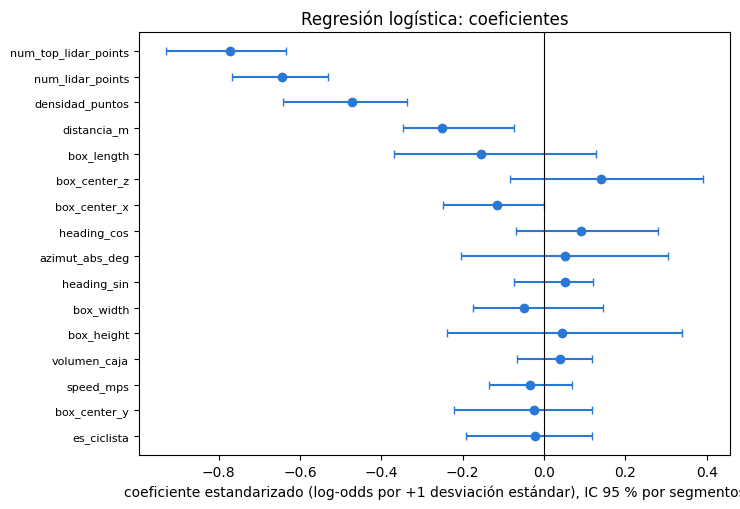

**Lectura en lenguaje de negocio (generada).** Las variables con mayor efecto en la regresión logística son `num_top_lidar_points`, `num_lidar_points`, `densidad_puntos`, `distancia_m`. En concreto: por cada desviación estándar más de puntos LiDAR de la parte alta (escala log), las probabilidades (odds) de que la caja no tenga par 2D se multiplican por 0,46 (IC 95 % 0,39 a 0,53); por cada desviación estándar más de puntos LiDAR (escala log), las probabilidades (odds) de que la caja no tenga par 2D se multiplican por 0,53 (IC 95 % 0,46 a 0,59); por cada desviación estándar más de densidad de puntos (escala log), las probabilidades (odds) de que la caja no tenga par 2D se multiplican por 0,62 (IC 95 % 0,53 a 0,71); por cada desviación estándar más de distancia al auto, las probabilidades (odds) de que la caja no tenga par 2D se multiplican por 0,78 (IC 95 % 0,71 a 0,93). 4 de 16 coeficientes tienen IC que excluye 0. Los odds ratio son por una desviación estándar (en escala log para las variables asimétricas) y describen asociación, no causa.

In [18]:
NOMBRES_NEGOCIO = {"box_center_x": "posición adelante-atrás (x)", "box_center_y": "posición lateral (y)", "box_center_z": "altura del centro de la caja (z)", "azimut_abs_deg": "ángulo respecto del frente del auto",
                   "distancia_m": "distancia al auto", "box_length": "largo de la caja", "box_width": "ancho de la caja", "box_height": "alto de la caja", "volumen_caja": "volumen de la caja (escala log)",
                   "num_lidar_points": "puntos LiDAR (escala log)", "num_top_lidar_points": "puntos LiDAR de la parte alta (escala log)", "densidad_puntos": "densidad de puntos (escala log)",
                   "speed_mps": "rapidez (de la etiqueta)", "heading_sin": "orientación (seno)", "heading_cos": "orientación (coseno)", "es_ciclista": "ser ciclista"}
lr_final = final["LR"]["modelo"]
nombres_feat = list(lr_final[0].get_feature_names_out())
coef = lr_final[-1].coef_[0]
t0 = time.time()
rng = np.random.default_rng(SEMILLA)
boot_coef = []
for b in range(150):
    ii = np.concatenate([idx_seg[j] for j in rng.integers(0, S_N, S_N)])
    mb = crear("LR", final["LR"]["cfg"]).fit(X.iloc[ii], y[ii])
    boot_coef.append(mb[-1].coef_[0])
boot_coef = np.array(boot_coef)
TIEMPOS["bootstrap_lr_s"] = time.time() - t0
lo, hi = np.percentile(boot_coef, [2.5, 97.5], axis=0)
tabla_lr = pd.DataFrame({"variable": nombres_feat, "coeficiente": coef, "IC lo": lo, "IC hi": hi, "odds ratio (+1 DE)": np.exp(coef), "OR lo": np.exp(lo), "OR hi": np.exp(hi)})
tabla_lr["significativa"] = (tabla_lr["IC lo"] > 0) | (tabla_lr["IC hi"] < 0)
tabla_lr = tabla_lr.reindex(tabla_lr["coeficiente"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print(tabla_lr.round(3).to_string(index=False))
tabla_lr.to_csv(RUTA_REPORTING / "09_coeficientes_lr.csv", index=False)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
t = tabla_lr[::-1]
ax.errorbar(t["coeficiente"], range(len(t)), xerr=[t["coeficiente"] - t["IC lo"], t["IC hi"] - t["coeficiente"]], fmt="o", color=AZUL, capsize=3)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(t)), t["variable"], fontsize=8)
ax.set_xlabel("coeficiente estandarizado (log-odds por +1 desviación estándar), IC 95 % por segmentos"); ax.set_title("Regresión logística: coeficientes")
fig.tight_layout()
guardar_fig(fig, "09_coeficientes_lr")
plt.show()
top = tabla_lr.head(4)
frases = []
for _, r in top.iterrows():
    nm = NOMBRES_NEGOCIO.get(r["variable"], r["variable"])
    frases.append(f"por cada desviación estándar más de {nm}, las probabilidades (odds) de que la caja no tenga par 2D se multiplican por {n2(r['odds ratio (+1 DE)'], 2)} (IC 95 % {n2(r['OR lo'], 2)} a {n2(r['OR hi'], 2)})")
RES["F"] = {"lr_top": top["variable"].tolist(), "n_signif": int(tabla_lr["significativa"].sum())}
display(Markdown(
    f"**Lectura en lenguaje de negocio (generada).** Las variables con mayor efecto en la regresión logística son " + ", ".join(f"`{v}`" for v in top["variable"]) + f". En concreto: " + "; ".join(frases) + ". "
    f"{RES['F']['n_signif']} de {len(tabla_lr)} coeficientes tienen IC que excluye 0. Los odds ratio son por una desviación estándar (en escala log para las variables asimétricas) y describen asociación, no causa."))

## F.2 Modelos de árboles: importancia por permutación y dependencia parcial

Importancia por permutación en el fold de validación (3 repeticiones por fold) del HGB y, si es el recomendado, del Random Forest. Dependencia parcial del modelo final sobre una muestra de train, comparada con la de la regresión logística.

Importancia por permutacion (caida media de AUC en validacion):
                         HGB
num_top_lidar_points  0.3094
speed_mps             0.0038
distancia_m           0.0025
volumen_caja          0.0024
densidad_puntos       0.0014
box_height            0.0010
box_center_x          0.0006
box_width             0.0002
box_length            0.0002
box_center_z          0.0000


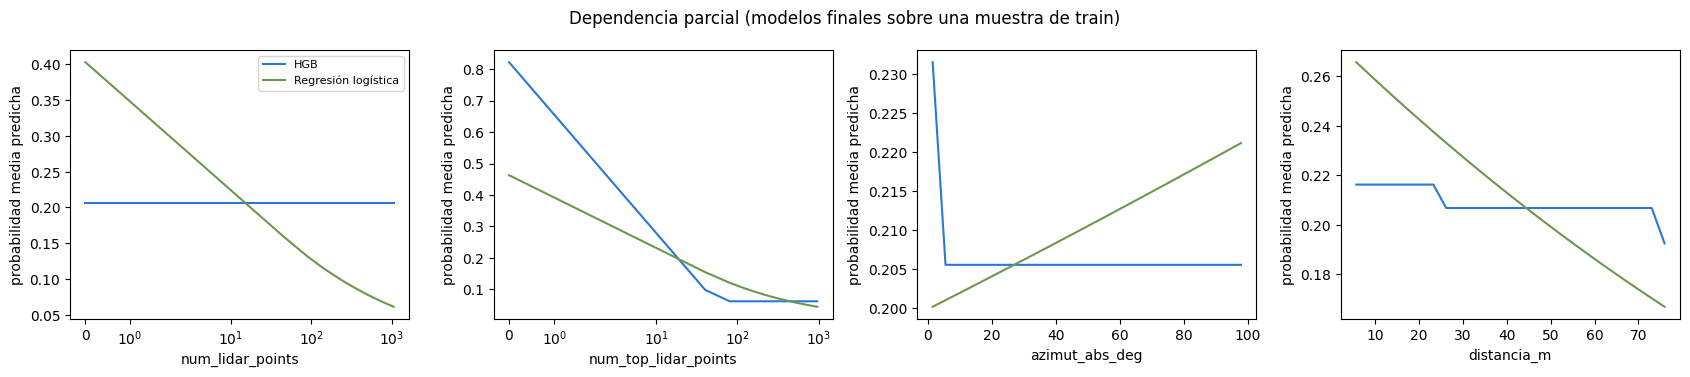

**Lectura (generada).** Importancia por permutación del HGB: `num_top_lidar_points` (0.309), `speed_mps` (0.004), `distancia_m` (0.002), `volumen_caja` (0.002), `densidad_puntos` (0.001). En el notebook 08 las tres variables más importantes fueron `num_top_lidar_points`, `azimut_abs_deg`, `densidad_puntos`; aquí son `num_top_lidar_points`, `speed_mps`, `distancia_m` (hay diferencias). Dependencia parcial frente a lo observado en los datos: `num_lidar_points`: la dependencia parcial del HGB cambia +0.000 de un extremo al otro y la tasa observada (primer a último quintil) cambia -0.626 (dependencia parcial plana (el modelo usa otras variables correlacionadas)); `num_top_lidar_points`: la dependencia parcial del HGB cambia -0.759 de un extremo al otro y la tasa observada (primer a último quintil) cambia -0.628 (mismo sentido); `azimut_abs_deg`: la dependencia parcial del HGB cambia -0.026 de un extremo al otro y la tasa observada (primer a último quintil) cambia -0.053 (mismo sentido); `distancia_m`: la dependencia parcial del HGB cambia -0.024 de un extremo al otro y la tasa observada (primer a último quintil) cambia +0.220 (sentido distinto). **La lectura del modelo no coincide en todas las variables** con la del análisis de datos del 08 (sentido distinto en: `distancia_m`). La tasa observada es marginal y la dependencia parcial es condicional a las demás variables; una diferencia de sentido puede deberse a esa distinción (por ejemplo, si las cajas más lejanas tienen menos puntos, el efecto marginal de la distancia incluye el de los puntos), y no necesariamente a una contradicción.

In [19]:
from sklearn.inspection import permutation_importance

arboles = ["HGB"] + (["RF"] if clave == "RF" else [])
imp = {}
t0 = time.time()
for nombre in arboles:
    acc = []
    for k in FOLDS:
        tr, va = folds != k, folds == k
        m = crear(nombre, busq[nombre][k]["cfg"]).fit(X[tr], y[tr])
        r = permutation_importance(m, X[va], y[va], scoring="roc_auc", n_repeats=3, random_state=SEMILLA, n_jobs=1)
        acc.append(r.importances_mean)
    imp[nombre] = pd.Series(np.mean(acc, axis=0), index=VARS).sort_values(ascending=False)
TIEMPOS["permutacion_s"] = time.time() - t0
imp_df = pd.DataFrame(imp)
print("Importancia por permutacion (caida media de AUC en validacion):")
print(imp_df.round(4).head(10).to_string())
imp_df.to_csv(RUTA_REPORTING / "09_importancia_permutacion.csv")

rng = np.random.default_rng(SEMILLA)
muestra = X.iloc[rng.choice(len(X), 6000, replace=False)].astype(float)
feats_pdp = ["num_lidar_points", "num_top_lidar_points", "azimut_abs_deg", "distancia_m"]
pdp = {}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, f in zip(axes, feats_pdp):
    for nombre, col in [("HGB", AZUL), ("LR", VERDE)]:
        r = partial_dependence(final[nombre]["modelo"], muestra, [f], kind="average", method="brute", response_method="predict_proba", grid_resolution=25, percentiles=(0.01, 0.99))
        pdp[(nombre, f)] = (r["grid_values"][0], r["average"][0])
        ax.plot(r["grid_values"][0], r["average"][0], color=col, label={"HGB": "HGB", "LR": "Regresión logística"}[nombre])
    ax.set_xlabel(f); ax.set_ylabel("probabilidad media predicha")   # response_method = predict_proba
    if f in ("num_lidar_points", "num_top_lidar_points"):
        ax.set_xscale("symlog")
axes[0].legend(fontsize=8)
fig.suptitle("Dependencia parcial (modelos finales sobre una muestra de train)")
fig.tight_layout()
guardar_fig(fig, "09_dependencia_parcial")
plt.show()

# contraste con lo observado (tasas en los datos) y con la importancia del 08
def tasa_extremos(col, q=5):
    g = df.groupby(pd.qcut(df[col], q, duplicates="drop"), observed=True)[TARGET].mean()
    return float(g.iloc[0]), float(g.iloc[-1])
obs = {f: tasa_extremos(f) for f in ["num_lidar_points", "num_top_lidar_points", "distancia_m"]}
obs["azimut_abs_deg"] = tasa_extremos("azimut_abs_deg")
coincide = {}
partes = []
for f in feats_pdp:
    g, a = pdp[("HGB", f)]
    pdp_cambio = float(a[-1] - a[0])
    obs_cambio = obs[f][1] - obs[f][0]
    plano = abs(pdp_cambio) < 0.01          # dependencia parcial practicamente plana: el modelo usa otra variable correlacionada
    coincide[f] = bool(plano or np.sign(pdp_cambio) == np.sign(obs_cambio))
    estado = "dependencia parcial plana (el modelo usa otras variables correlacionadas)" if plano else ("mismo sentido" if coincide[f] else "sentido distinto")
    partes.append(f"`{f}`: la dependencia parcial del HGB cambia {pdp_cambio:+.3f} de un extremo al otro y la tasa observada (primer a último quintil) cambia {obs_cambio:+.3f} ({estado})")
try:
    imp08 = pd.read_csv(RUTA_REPORTING / "08_importancia_permutacion.csv", index_col=0).iloc[:, 0].sort_values(ascending=False)
    top08 = imp08.head(3).index.tolist()
    txt08 = f"En el notebook 08 las tres variables más importantes fueron {', '.join(f'`{v}`' for v in top08)}; aquí son {', '.join(f'`{v}`' for v in imp['HGB'].head(3).index)}" + (" (coinciden en al menos dos)." if len(set(top08) & set(imp['HGB'].head(3).index)) >= 2 else " (hay diferencias).")
except Exception as e:
    txt08 = "No se pudo leer la importancia del 08."
RES["F"].update({"top_arbol": imp["HGB"].head(3).index.tolist(), "coincide": coincide})
display(Markdown(
    f"**Lectura (generada).** Importancia por permutación del HGB: " + ", ".join(f"`{v}` ({x:.3f})" for v, x in imp["HGB"].head(5).items()) + ". " + txt08 + " "
    "Dependencia parcial frente a lo observado en los datos: " + "; ".join(partes) + ". " +
    ("**La lectura del modelo coincide con la del análisis de datos (A.1 a A.5 del 08)** en el sentido de las cuatro variables." if all(coincide.values()) else
     f"**La lectura del modelo no coincide en todas las variables** con la del análisis de datos del 08 (sentido distinto en: {', '.join(f'`{f}`' for f, v in coincide.items() if not v)}). La tasa observada es marginal y la dependencia parcial es condicional a las demás variables; "
     "una diferencia de sentido puede deberse a esa distinción (por ejemplo, si las cajas más lejanas tienen menos puntos, el efecto marginal de la distancia incluye el de los puntos), y no necesariamente a una contradicción.")))

## F.3 Análisis de errores del modelo recomendado (punto A)

In [20]:
fl = BANDERAS[clave]["A"]
tipo = np.select([fl & (y == 1), ~fl & (y == 1), fl & (y == 0)], ["acierto (TP)", "falso negativo (FN)", "falso positivo (FP)"], "TN")
df_e = df.assign(tipo=tipo, score=oof[clave])
perfil = df_e.groupby("tipo").agg(filas=("tipo", "size"), pct_ciclistas=("es_ciclista", lambda s: s.mean() * 100), distancia_med=("distancia_m", "median"), azimut_med=("azimut_abs_deg", "median"),
                                  puntos_med=("num_lidar_points", "median"), puntos_top_med=("num_top_lidar_points", "median"), pct_franja_100_120=("azimut_abs_deg", lambda s: (s > 100).mean() * 100),
                                  segmentos=(GRUPO, "nunique")).round(2)
print(perfil.to_string())
fn = df_e[df_e["tipo"] == "falso negativo (FN)"]
por_seg = fn.groupby(GRUPO).size().sort_values(ascending=False)
top_seg = (por_seg.head(3) / len(fn)).round(3)
print("\nSegmentos con mas falsos negativos (fraccion de los FN):", {k[:12]: float(v) for k, v in top_seg.items()})
cols_ej = [GRUPO, "key.frame_timestamp_micros", "es_ciclista", "num_lidar_points", "num_top_lidar_points", "distancia_m", "azimut_abs_deg", "score"]
mediana_pts = df_e["num_lidar_points"].median()
ejemplos = pd.concat([fn[fn["num_lidar_points"] >= mediana_pts].nsmallest(2, "score").assign(caso="FN bien observado (muchos puntos) y puntaje bajo"),
                      df_e[df_e["tipo"] == "falso positivo (FP)"].nlargest(2, "score").assign(caso="FP con puntaje alto"),
                      fn.nsmallest(1, "score").assign(caso="FN con el puntaje mas bajo")])
ejemplos["segmento"] = ejemplos[GRUPO].str[:12]
print("\nEjemplos de frames dificiles:")
print(ejemplos[["caso", "segmento", "key.frame_timestamp_micros", "es_ciclista", "num_lidar_points", "num_top_lidar_points", "distancia_m", "azimut_abs_deg", "score"]].round(3).to_string(index=False))
ejemplos[["caso"] + cols_ej].to_csv(RUTA_REPORTING / "09_ejemplos_errores.csv", index=False)
perfil.to_csv(RUTA_REPORTING / "09_perfil_errores.csv")
tp, fnp, fpp = perfil.loc["acierto (TP)"], perfil.loc["falso negativo (FN)"], perfil.loc["falso positivo (FP)"]
RES["F"].update({"fn_top_seg": float(top_seg.iloc[0]), "fn_pts": float(fnp["puntos_med"]), "tp_pts": float(tp["puntos_med"]), "fp_pts": float(fpp["puntos_med"])})
desc = "; ".join(f"{r['caso']}: segmento {r['segmento']}, {'ciclista' if r['es_ciclista'] else 'peatón'}, {int(r['num_lidar_points'])} puntos ({int(r['num_top_lidar_points'])} en la parte alta), a {n2(r['distancia_m'], 1)} m y {n2(r['azimut_abs_deg'], 0)}°, puntaje {n2(r['score'], 3)}" for _, r in ejemplos.iterrows())
display(Markdown(
    f"**Lectura (generada).** Al punto A hay {miles(fnp['filas'])} falsos negativos y {miles(fpp['filas'])} falsos positivos. Los falsos negativos tienen una mediana de {int(fnp['puntos_med'])} puntos (aciertos: {int(tp['puntos_med'])}; falsos positivos: {int(fpp['puntos_med'])}), "
    f"están a {n2(fnp['distancia_med'], 1)} m (aciertos: {n2(tp['distancia_med'], 1)} m) y el {n2(fnp['pct_franja_100_120'], 1)} % cae en 100–120° (aciertos: {n2(tp['pct_franja_100_120'], 1)} %). "
    f"El segmento con más falsos negativos concentra el {pct(float(top_seg.iloc[0]))} de ellos. Ejemplos: {desc}."))

                     filas  pct_ciclistas  distancia_med  azimut_med  puntos_med  puntos_top_med  pct_franja_100_120  segmentos
tipo                                                                                                                           
TN                   36872           3.14          28.36       27.38        77.0            76.0                 0.0         33
acierto (TP)         10830           0.44          48.83       20.77         3.0             3.0                 0.0         30
falso negativo (FN)   2538           2.52          36.98       17.52        43.0            43.0                 0.0         23
falso positivo (FP)  14269           1.51          48.27       17.05        15.0            15.0                 0.0         33

Segmentos con mas falsos negativos (fraccion de los FN): {'181366958272': 0.193, '734453671207': 0.16, '247562357599': 0.152}

Ejemplos de frames dificiles:
                                            caso     segmento  key.frame_t

**Lectura (generada).** Al punto A hay 2.538 falsos negativos y 14.269 falsos positivos. Los falsos negativos tienen una mediana de 43 puntos (aciertos: 3; falsos positivos: 15), están a 37,0 m (aciertos: 48,8 m) y el 0,0 % cae en 100–120° (aciertos: 0,0 %). El segmento con más falsos negativos concentra el 19,3 % de ellos. Ejemplos: FN bien observado (muchos puntos) y puntaje bajo: segmento 158823431340, ciclista, 1174 puntos (989 en la parte alta), a 7,2 m y 37°, puntaje 0,002; FN bien observado (muchos puntos) y puntaje bajo: segmento 158823431340, ciclista, 1125 puntos (955 en la parte alta), a 6,9 m y 38°, puntaje 0,003; FP con puntaje alto: segmento 911012534050, peatón, 0 puntos (0 en la parte alta), a 42,3 m y 31°, puntaje 0,995; FP con puntaje alto: segmento 911012534050, peatón, 0 puntos (0 en la parte alta), a 43,5 m y 32°, puntaje 0,995; FN con el puntaje mas bajo: segmento 158823431340, ciclista, 1174 puntos (989 en la parte alta), a 7,2 m y 37°, puntaje 0,002.

# G. Equidad y robustez

**Por qué importa.** Un modelo que funciona en promedio puede fallar en una condición concreta. Se mide AUC y recall al punto A por grupo con los folds de train (no el test), con un mínimo de filas por grupo, y la brecha máxima. Solo se reporta lo medido.

In [21]:
cr_s = CRIT["estabilidad"]
def tabla_grupo(col):
    filas = []
    for v in sorted(df[col].unique()):
        m = (df[col] == v).values
        n1, n0 = int(y[m].sum()), int((1 - y[m]).sum())
        auc = roc_auc_score(y[m], sc_rec[m]) if min(n1, n0) >= cr_s["min_filas_clase_segmento"] else np.nan
        mt = metricas_flags(BANDERAS[clave]["A"][m], y[m])
        filas.append({"variable": col, "grupo": v, "segmentos": int(df.loc[m, GRUPO].nunique()), "filas": int(m.sum()), "sin_camara": n1, "AUC": auc, "recall_A": mt["recall"] if n1 >= CRIT["operacion"]["min_positivos_segmento"] else np.nan,
                      "precision_A": mt["precision"], "pct_revisar_A": mt["pct_revisar"]})
    return pd.DataFrame(filas)

df["object_type_"] = np.where(df["es_ciclista"] == 1, "CYCLIST", "PEDESTRIAN")
equi = pd.concat([tabla_grupo(c) for c in ["time_of_day", "location", "object_type_"]], ignore_index=True)
print(f"Equidad por grupo ({NOMBRE[clave]}, punto A; AUC solo con >= {cr_s['min_filas_clase_segmento']} filas por clase, recall solo con >= {CRIT['operacion']['min_positivos_segmento']} positivos):")
print(equi.round(3).to_string(index=False))
equi.to_csv(RUTA_REPORTING / "09_equidad.csv", index=False)
def gap_ci(g_a, g_b, n_boot=300, seed=SEMILLA):
    # diferencia g_a - g_b en AUC y en recall al punto A; bootstrap estratificado: se remuestrean segmentos dentro de cada grupo de momento del dia
    fl = BANDERAS[clave]["A"]
    segs = {g: [a for a in (idx_seg[si][(df.loc[idx_seg[si], "time_of_day"] == g).values] for si in range(S_N)) if len(a)] for g in (g_a, g_b)}

    def met(ii):
        yy = y[ii]
        return (roc_auc_score(yy, sc_rec[ii]) if len(np.unique(yy)) > 1 else np.nan), float((fl[ii] & (yy == 1)).sum() / max(yy.sum(), 1))
    pt = {g: met(np.concatenate(segs[g])) for g in segs}
    rng = np.random.default_rng(seed)
    dA, dR = [], []
    for _ in range(n_boot):
        mm = {g: met(np.concatenate([segs[g][j] for j in rng.integers(0, len(segs[g]), len(segs[g]))])) for g in segs}
        dA.append(mm[g_a][0] - mm[g_b][0]); dR.append(mm[g_a][1] - mm[g_b][1])
    return {"n_seg": {g: len(v) for g, v in segs.items()}, "filas": {g: int(sum(len(a) for a in v)) for g, v in segs.items()},
            "auc": (pt[g_a][0] - pt[g_b][0], *np.nanpercentile(dA, [2.5, 97.5])), "recall": (pt[g_a][1] - pt[g_b][1], *np.nanpercentile(dR, [2.5, 97.5]))}


gaps = {f"{a} menos {b}": gap_ci(a, b) for a, b in [("Dawn/Dusk", "Day"), ("Night", "Day")]}
for n_, g_ in gaps.items():
    print(f"{n_}: segmentos {g_['n_seg']} | filas {g_['filas']} | AUC {g_['auc'][0]:+.3f} (IC {g_['auc'][1]:+.3f} a {g_['auc'][2]:+.3f}) | recall al punto A {g_['recall'][0]:+.3f} (IC {g_['recall'][1]:+.3f} a {g_['recall'][2]:+.3f})")
brechas = {}
for c in ["time_of_day", "location"]:
    e = equi[equi["variable"] == c]
    brechas[c] = {"auc": float(e["AUC"].max() - e["AUC"].min()) if e["AUC"].notna().sum() >= 2 else np.nan, "recall": float(e["recall_A"].max() - e["recall_A"].min()) if e["recall_A"].notna().sum() >= 2 else np.nan,
                  "grupos": int(e["AUC"].notna().sum())}
t_seg, ev_seg, minimo = por_segmento_auc(sc_rec)
q1, med, q3 = ev_seg["auc"].quantile([0.25, 0.5, 0.75])
RES["G"] = {"gaps": gaps, "brechas": brechas, "seg_n": len(ev_seg), "seg_med": float(med), "seg_q": (float(q1), float(q3)), "seg_min": float(ev_seg["auc"].min()), "seg_max": float(ev_seg["auc"].max())}
cic = equi[(equi["variable"] == "object_type_") & (equi["grupo"] == "CYCLIST")].iloc[0]
display(Markdown(
    "**Lectura (generada, sin juicios más allá de lo medido).** " + " ".join(
        f"Por {'momento del día' if c == 'time_of_day' else 'ubicación'}: brecha máxima de AUC {n2(b['auc'], 3)} (entre {b['grupos']} grupos evaluables) y de recall al punto A {n2(b['recall'], 3)}." for c, b in brechas.items()) +
    f" Por segmento ({len(ev_seg)} evaluables con ≥ {minimo} filas por clase) la mediana del AUC es {n2(med, 3)} (IQR {n2(q1, 3)}–{n2(q3, 3)}; rango {n2(ev_seg['auc'].min(), 3)} a {n2(ev_seg['auc'].max(), 3)}). "
    " Brechas con IC 95 % por segmentos (bootstrap estratificado por grupo): " + "; ".join(
        f"{n_} (segmentos: {' y '.join(f'{k} {v}' for k, v in g_['n_seg'].items())}; filas: {' y '.join(f'{k} {miles(v)}' for k, v in g_['filas'].items())}): AUC {g_['auc'][0]:+.3f} (IC {g_['auc'][1]:+.3f} a {g_['auc'][2]:+.3f}) y recall al punto A {g_['recall'][0]:+.3f} (IC {g_['recall'][1]:+.3f} a {g_['recall'][2]:+.3f})" for n_, g_ in gaps.items()) + ". " +
    f"**Ciclistas, con cautela** ({miles(cic['filas'])} filas, {int(cic['sin_camara'])} `sin_camara`): recall al punto A {n2(cic['recall_A'], 3) if not np.isnan(cic['recall_A']) else 'no evaluable (menos de 50 positivos)'}; el AUC " +
    ("no es evaluable con tan pocas filas por clase." if np.isnan(cic["AUC"]) else f"es {n2(cic['AUC'], 3)}.")))

Equidad por grupo (Regresion logistica, punto A; AUC solo con >= 200 filas por clase, recall solo con >= 50 positivos):
    variable          grupo  segmentos  filas  sin_camara   AUC  recall_A  precision_A  pct_revisar_A
 time_of_day      Dawn/Dusk         10  14766        3013 0.787     0.714        0.402          0.362
 time_of_day            Day         12  31028        5456 0.866     0.862        0.358          0.424
 time_of_day          Night         11  18715        4899 0.871     0.811        0.603          0.352
    location location_other          5   4239         540 0.920     0.906        0.416          0.277
    location   location_phx         15  10566        1668 0.859     0.914        0.312          0.462
    location    location_sf         13  49704       11160 0.818     0.790        0.463          0.383
object_type_        CYCLIST         12   1483         112   NaN     0.429        0.183          0.177
object_type_     PEDESTRIAN         32  63026       13256 0.828 

Dawn/Dusk menos Day: segmentos {'Dawn/Dusk': 10, 'Day': 12} | filas {'Dawn/Dusk': 14766, 'Day': 31028} | AUC -0.080 (IC -0.196 a +0.083) | recall al punto A -0.148 (IC -0.255 a +0.061)
Night menos Day: segmentos {'Night': 11, 'Day': 12} | filas {'Night': 18715, 'Day': 31028} | AUC +0.005 (IC -0.082 a +0.134) | recall al punto A -0.051 (IC -0.151 a +0.100)


**Lectura (generada, sin juicios más allá de lo medido).** Por momento del día: brecha máxima de AUC 0,084 (entre 3 grupos evaluables) y de recall al punto A 0,148. Por ubicación: brecha máxima de AUC 0,102 (entre 3 grupos evaluables) y de recall al punto A 0,124. Por segmento (14 evaluables con ≥ 200 filas por clase) la mediana del AUC es 0,888 (IQR 0,839–0,938; rango 0,390 a 0,983).  Brechas con IC 95 % por segmentos (bootstrap estratificado por grupo): Dawn/Dusk menos Day (segmentos: Dawn/Dusk 10 y Day 12; filas: Dawn/Dusk 14.766 y Day 31.028): AUC -0.080 (IC -0.196 a +0.083) y recall al punto A -0.148 (IC -0.255 a +0.061); Night menos Day (segmentos: Night 11 y Day 12; filas: Night 18.715 y Day 31.028): AUC +0.005 (IC -0.082 a +0.134) y recall al punto A -0.051 (IC -0.151 a +0.100). **Ciclistas, con cautela** (1.483 filas, 112 `sin_camara`): recall al punto A 0,429; el AUC no es evaluable con tan pocas filas por clase.

# H. Sensibilidad: población de 120 grados

**Por qué importa.** La población principal es |azimut| ≤ 100° porque en 100–120° la ausencia de par 2D es en buena parte geométrica (notebook 08). Acá se repite la comparación en la población anterior (|azimut| ≤ 120°, toda B) **incluyendo los baselines geométricos**, para ver si en esa población el modelo supera a la regla geométrica y no solo a la regla de puntos. Los modelos se **reentrenan** con los hiperparámetros ya elegidos (sin nueva búsqueda) y los mismos folds.

In [22]:
dfH = df_full.reset_index(drop=True)
yH, foldsH = dfH[TARGET].values, dfH["fold"].values.astype(int)
XH = dfH[VARS].copy()
seg_codesH, seg_nombresH = pd.factorize(dfH[GRUPO])
POB_H = {"y": yH, "tb": np.random.default_rng(SEMILLA).random(len(dfH)), "seg": seg_codesH, "n_seg": len(seg_nombresH)}
azH = dfH["azimut_abs_deg"].values
s_reglaH = -dfH["num_lidar_points"].values.astype(float)
s_topH = -dfH["num_top_lidar_points"].values.astype(float)
s_geomH = np.where(azH > UMBRAL_GEOM, 1e6, 0.0) + s_reglaH
s_minH = np.zeros(len(yH))
sH = {m: np.zeros(len(yH)) for m in MODELOS}
t0 = time.time()
for k in FOLDS:
    tr, va = foldsH != k, foldsH == k
    s_minH[va] = crear_min().fit(dfH.loc[tr, VARS_MIN], yH[tr]).predict_proba(dfH.loc[va, VARS_MIN])[:, 1]
    for nombre in MODELOS:
        sH[nombre][va] = pred(crear(nombre, final[nombre]["cfg"]).fit(XH[tr], yH[tr]), XH[va])
TIEMPOS["sensibilidad_s"] = time.time() - t0
scores_H = {"Prevalencia (trivial)": np.full(len(yH), yH.mean()), N_REGLA: s_reglaH, N_GEOM: s_geomH, N_MIN: s_minH, N_TOP: s_topH, **{NOMBRE_MOD[m]: s for m, s in sH.items()}}
punto_H, boot_H = boot_all(scores_H, pob=POB_H)
auc_H = {n: punto_H[n]["AUC"] for n in SIMPLES}
BASE_H = max(SIMPLES, key=lambda n: (round(auc_H[n], 12), -SIMPLES.index(n)))
filas = []
for n in scores_H:
    f = {"metodo": n, "poblacion": "120 (toda B)"}
    for m in MET:
        lo, hi = ic(boot_H[n][m])
        f[m] = f"{punto_H[n][m]:.3f} ({lo:.3f} a {hi:.3f})"
    filas.append(f)
tabla_H = pd.DataFrame(filas)
print(f"Poblacion de sensibilidad: {len(yH):,} filas, {len(seg_nombresH)} segmentos | mejor baseline simple en esta poblacion: {BASE_H}")
print(tabla_H.to_string(index=False))
tabla_H.to_csv(RUTA_REPORTING / "09_sensibilidad_120.csv", index=False)

def vlp_pob(n, base):
    dA, dF = delta(punto_H, boot_H, n, base, "AUC"), delta(punto_H, boot_H, n, base, "Fraccion para 80%")
    return bool(dF[0] <= cr_v["delta_fraccion80_max"] and dF[2] < 0 and dA[0] >= cr_v["delta_auc_min"]), dA, dF

vlp_H = {n: vlp_pob(n, BASE_H) for n in MODS}
filas = []
for n in MODS:
    for b in SIMPLES:
        dA, dF = delta(punto_H, boot_H, n, b, "AUC"), delta(punto_H, boot_H, n, b, "Fraccion para 80%")
        filas.append({"modelo menos baseline": f"{n} menos {b}", "dAUC": f"{dA[0]:+.3f} ({dA[1]:+.3f} a {dA[2]:+.3f})", "dFraccion80 (puntos)": f"{dF[0] * 100:+.1f} ({dF[1] * 100:+.1f} a {dF[2] * 100:+.1f})"})
print("\nDiferencias de cada modelo contra cada baseline simple (poblacion de 120, IC pareado por segmentos):")
print(pd.DataFrame(filas).to_string(index=False))
dif_geom = {n: delta(punto_H, boot_H, n, N_GEOM, "Fraccion para 80%") for n in MODS}
dif_pts = {n: delta(punto_H, boot_H, n, N_REGLA, "Fraccion para 80%") for n in MODS}
robustos = [n for n in MODS if vlp[n][0] and vlp_H[n][0]]
RES["H"] = {"n": len(yH), "base_H": BASE_H, "vlp_H": {n: v[0] for n, v in vlp_H.items()}, "robustos": robustos, "dif_geom": dif_geom, "dif_pts": dif_pts, "auc_H": auc_H,
            "rank_c": sorted(scores_H, key=lambda n: -punto_H[n]["AUC"])}
partes = []
for n in MODS:
    g, pt_ = dif_geom[n], dif_pts[n]
    partes.append(f"**{n}**: contra la regla de puntos {pt_[0] * 100:+.1f} puntos en Fracción para 80 % (IC {pt_[1] * 100:+.1f} a {pt_[2] * 100:+.1f}) y contra la regla geométrica {g[0] * 100:+.1f} (IC {g[1] * 100:+.1f} a {g[2] * 100:+.1f})")
display(Markdown(
    f"**Lectura (generada).** En la población de 120° ({miles(len(yH))} filas) el mejor baseline simple es **{BASE_H}** (AUC {n2(auc_H[BASE_H], 3)}). " + "; ".join(partes) + ". " +
    f"Frente al mejor baseline de esa población, " + ("; ".join(f"{n} {'**vale la pena**' if vlp_H[n][0] else '**no vale la pena**'}" for n in MODS)) + ". " +
    f"Modelos **robustos** (valen la pena en la población principal y en la de 120°): " + (", ".join(robustos) if robustos else "**ninguno**") + "."))

Poblacion de sensibilidad: 68,555 filas, 33 segmentos | mejor baseline simple en esta poblacion: Regla geometrica (azimut > 105 primero)
                                 metodo    poblacion                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
                  Prevalencia (trivial) 120 (toda B) 0.500 (0.500 a 0.500) 0.232 (0.192 a 0.272) 0.197 (0.190 a 0.204) 0.802 (0.799 a 0.805)
              Regla: menos puntos LiDAR 120 (toda B) 0.797 (0.748 a 0.847) 0.661 (0.555 a 0.735) 0.579 (0.507 a 0.665) 0.505 (0.405 a 0.607)
Regla geometrica (azimut > 105 primero) 120 (toda B) 0.862 (0.821 a 0.900) 0.689 (0.601 a 0.755) 0.639 (0.571 a 0.726) 0.368 (0.262 a 0.443)
         Modelo minimo (LR 3 variables) 120 (toda B) 0.831 (0.775 a 0.889) 0.689 (0.580 a 0.783) 0.578 (0.493 a 0.685) 0.437 (0.307 a 0.536)
                Regla: menos puntos top 120 (toda B) 0.800 (0.751 a 0.852) 0.668 (0.561 a 0.743) 0.582 (0.510 a 0.669) 0.499 (0.394 a 0.602)
                 

**Lectura (generada).** En la población de 120° (68.555 filas) el mejor baseline simple es **Regla geometrica (azimut > 105 primero)** (AUC 0,862). **Regresion logistica**: contra la regla de puntos -6.4 puntos en Fracción para 80 % (IC -16.5 a -0.7) y contra la regla geométrica +7.3 (IC +1.9 a +11.4); **HGB**: contra la regla de puntos -9.0 puntos en Fracción para 80 % (IC -20.0 a -2.0) y contra la regla geométrica +4.8 (IC -1.3 a +9.1); **Random Forest**: contra la regla de puntos -8.9 puntos en Fracción para 80 % (IC -20.8 a -2.9) y contra la regla geométrica +4.9 (IC -1.6 a +9.3). Frente al mejor baseline de esa población, Regresion logistica **no vale la pena**; HGB **no vale la pena**; Random Forest **no vale la pena**. Modelos **robustos** (valen la pena en la población principal y en la de 120°): **ninguno**.

# I. Conclusiones

In [23]:
c_, d_, e_, f_, g_, h_ = RES["C"], RES["D"], RES["E"], RES["F"], RES["G"], RES["H"]
vlp_p = c_["vlp"]
modelo_ok = recomendado in h_["robustos"]
RECOMENDACION = recomendado if modelo_ok else REGLA
ap, ab = punto_c[recomendado], punto_c[REGLA]
dA_rec, dF_rec = delta(punto_c, boot_c, recomendado, REGLA, "AUC"), delta(punto_c, boot_c, recomendado, REGLA, "Fraccion para 80%")
rec_txt = (f"**Recomendación final: {RECOMENDACION}.** " +
           (f"El mejor modelo ({recomendado}) es robusto: vale la pena frente al mejor baseline simple en la población principal y en la de 120°." if modelo_ok else
            f"Ningún modelo es robusto frente al mejor baseline simple: el mejor modelo ({recomendado}) " + ("vale la pena en la población principal" if vlp_p[recomendado] else "no vale la pena en la población principal") + " y " +
            ("vale la pena en la de 120°" if h_["vlp_H"][recomendado] else "no vale la pena en la de 120°") + f". Se recomienda el baseline simple **{REGLA}** por simplicidad y explicabilidad; los modelos quedan como comparación.") +
           f" En la población principal el mejor modelo ({recomendado}) tiene AUC {n2(ap['AUC'], 3)}, PR-AUC {n2(ap['PR-AUC'], 3)}, Captura@20 % {pct(ap['Captura@20%'])} y Fracción para 80 % {pct(ap['Fraccion para 80%'])}; el baseline ({REGLA}), AUC {n2(ab['AUC'], 3)} y Fracción para 80 % {pct(ab['Fraccion para 80%'])}. "
           f"Diferencia modelo menos baseline: AUC {dA_rec[0]:+.3f} (IC {dA_rec[1]:+.3f} a {dA_rec[2]:+.3f}) y Fracción para 80 % {dF_rec[0] * 100:+.1f} puntos (IC {dF_rec[1] * 100:+.1f} a {dF_rec[2] * 100:+.1f}).")
conclusion = [
    rec_txt,
    f"Estabilidad del mejor modelo ({recomendado}): AUC mínimo por fold {n2(c_['auc_min_fold'], 3)} y mediana del AUC por segmento {n2(c_['mediana_segmento'], 3)} → " + ("cumple los umbrales fijados." if c_["estable"] else "no cumple al menos uno de los umbrales fijados."),
    f"Punto A (recall 0,80 fijado con train, mejor modelo {recomendado}): recall {n2(d_['A']['recall'], 3)} (IC {n2(d_['ic']['recall'][0], 3)} a {n2(d_['ic']['recall'][1], 3)}), precisión {n2(d_['A']['precision'], 3)}, {pct(d_['A']['pct_revisar'])} de los frames a revisar; el baseline ({REGLA}) con el mismo método revisa el {pct(d_['A_regla']['pct_revisar'])} para un recall de {n2(d_['A_regla']['recall'], 3)}.",
    f"Calibración: ECE crudo {n2(e_['ece_crudo'], 3)}; mejor versión {e_['mejor']} con ECE {n2(min(e_['ece_platt'], e_['ece_iso']), 3)} ({'cumple' if e_['ok'] else 'no cumple'} el umbral de 0,05).",
    f"Interpretación: variables principales de la regresión logística {', '.join(f'`{v}`' for v in f_['lr_top'][:3])}; del HGB {', '.join(f'`{v}`' for v in f_['top_arbol'])}. La lectura " + ("coincide" if all(f_["coincide"].values()) else "no coincide del todo") + " con el análisis de datos del 08.",
    f"Sensibilidad (población de 120°, {miles(h_['n'])} filas): mejor baseline simple {h_['base_H']}; modelos que valen la pena frente a él: " + (", ".join(n for n, v in h_["vlp_H"].items() if v) or "ninguno") + "; robustos: " + (", ".join(h_["robustos"]) or "ninguno") + ".",
    RES["C2"]["resumen"],
]
cfg_eval = {m: [busq[m][k]["n_evaluadas"] for k in FOLDS] for m in MODELOS}
txt_cfg = "; ".join(f"{NOMBRE_MOD[m]}: {', '.join(str(v) for v in cfg_eval[m])} configuraciones reales por fold (ajuste final: {final[m]['n_evaluadas']})" for m in MODELOS)
limitaciones = ["La etiqueta mide cobertura de etiquetado, no visibilidad física de la cámara.",
                f"La población principal (|azimut| ≤ {AZ_MAX}°) excluye {miles(len(df_full) - len(df))} filas ({pct(1 - len(df) / len(df_full))}) cuya ausencia de par 2D es en buena parte geométrica; el borde de 100° es empírico y no se pudo confirmar con la calibración de las cámaras (`camera_calibration` no está disponible localmente).",
                "Los folds se estratificaron por `tiene_camara`, no por `sin_camara` en la zona de cámaras; la prevalencia varía entre folds.",
                f"Pocos ciclistas ({miles(cic['filas'])} filas en la población principal): las métricas por clase son frágiles.",
                "La composición del test se conoce solo por conteos (8 segmentos, con un solo segmento Night y uno Dawn/Dusk); la equidad por momento del día se midió con los folds de train.",
                "SMOTE y SHAP no se usaron porque `imbalanced-learn` y `shap` no están instalados." + (" El Random Forest se omitió por tiempo." if RF_OMITIDO else ""),
                f"La búsqueda de hiperparámetros es acotada: {txt_cfg}. Es una búsqueda aleatoria sobre un espacio limitado (con grilla para la regresión logística), no exhaustiva.",
                "El AUC agrupado mezcla cinco modelos distintos (uno por fold); por eso se agregó el diagnóstico por fold y por segmento (C.2): que un modelo «no valga la pena» frente al baseline según los criterios fijados no equivale a que sea peor."]
para10 = [f"Se llevan al 10 los modelos ajustados sobre todo train en la población principal (`data/06_models/{', '.join(guardados)}`), el calibrador y los umbrales A, B y F1 fijados con train (en `hiperparametros_B.json`, para los modelos y para el baseline), **sin reajuste** en test.",
          f"La recomendación final es **{RECOMENDACION}**; el mejor baseline simple ({REGLA}) y el modelo mínimo se evalúan en test como referencia obligatoria.",
          "El plan de evaluación del test queda congelado en `data/06_models/plan_evaluacion_test.json` y `docs/plan_evaluacion_test.md` (sección J), con las sumas de verificación de los modelos."]
abiertas = [f"¿Se sostiene en test la conclusión sobre el mejor baseline simple y los modelos, dado que el test tiene {len(SEGS_TEST)} segmentos con un etiquetado muy desigual?",
            "¿Qué punto de operación (A, B o F1) se adopta, y con qué costo de revisión real (el supuesto de 20 s por revisión no es un dato)?",
            f"¿Se confirma el borde de {AZ_MAX}° con la calibración de las cámaras (`camera_calibration`)?",
            "¿Cómo se reporta la equidad por momento del día con un solo segmento Night y uno Dawn/Dusk en el test?"]
display(Markdown("### Recomendación y evidencia\n\n" + "\n".join(f"{i + 1}. {t}" for i, t in enumerate(conclusion))))
display(Markdown("### Qué se lleva al 10\n\n" + "\n".join(f"- {t}" for t in para10)))
display(Markdown("### Limitaciones\n\n" + "\n".join(f"- {t}" for t in limitaciones)))
display(Markdown("### Preguntas abiertas para el 10\n\n" + "\n".join(f"- {t}" for t in abiertas)))

### Recomendación y evidencia

1. **Recomendación final: Regla: menos puntos top.** Ningún modelo es robusto frente al mejor baseline simple: el mejor modelo (Regresion logistica) no vale la pena en la población principal y no vale la pena en la de 120°. Se recomienda el baseline simple **Regla: menos puntos top** por simplicidad y explicabilidad; los modelos quedan como comparación. En la población principal el mejor modelo (Regresion logistica) tiene AUC 0,825, PR-AUC 0,657, Captura@20 % 58,1 % y Fracción para 80 % 43,7 %; el baseline (Regla: menos puntos top), AUC 0,862 y Fracción para 80 % 37,8 %. Diferencia modelo menos baseline: AUC -0.036 (IC -0.056 a -0.007) y Fracción para 80 % +5.8 puntos (IC -0.8 a +10.6).
2. Estabilidad del mejor modelo (Regresion logistica): AUC mínimo por fold 0,811 y mediana del AUC por segmento 0,888 → cumple los umbrales fijados.
3. Punto A (recall 0,80 fijado con train, mejor modelo Regresion logistica): recall 0,810 (IC 0,761 a 0,874), precisión 0,431, 38,9 % de los frames a revisar; el baseline (Regla: menos puntos top) con el mismo método revisa el 37,9 % para un recall de 0,806.
4. Calibración: ECE crudo 0,044; mejor versión Platt con ECE 0,013 (cumple el umbral de 0,05).
5. Interpretación: variables principales de la regresión logística `num_top_lidar_points`, `num_lidar_points`, `densidad_puntos`; del HGB `num_top_lidar_points`, `speed_mps`, `distancia_m`. La lectura no coincide del todo con el análisis de datos del 08.
6. Sensibilidad (población de 120°, 68.555 filas): mejor baseline simple Regla geometrica (azimut > 105 primero); modelos que valen la pena frente a él: ninguno; robustos: ninguno.
7. Diagnóstico (C.2): la brecha agrupada de AUC entre modelo y regla de puntos es mucho mayor que la brecha por fold y por segmento; por fold y por segmento los IC incluyen 0 para Regresion logistica, HGB, Random Forest, así que **el modelo no se distingue de la regla de puntos**. Frente al mejor baseline simple (Regla: menos puntos top): Regresion logistica: el modelo no se distingue de la regla; HGB: la evidencia es mixta (un IC incluye 0 y el otro no); Random Forest: el modelo no se distingue de la regla. El veredicto de los criterios fijados antes (frente al mejor baseline simple: Regresion logistica: no vale la pena, HGB: no vale la pena, Random Forest: no vale la pena) no cambia: lo que cambia es su alcance, porque «no vale la pena» no equivale a «es peor».

### Qué se lleva al 10

- Se llevan al 10 los modelos ajustados sobre todo train en la población principal (`data/06_models/lr_B.joblib, hgb_B.joblib, calibrador_B.joblib, lr_minimo_B.joblib, rf_B.joblib`), el calibrador y los umbrales A, B y F1 fijados con train (en `hiperparametros_B.json`, para los modelos y para el baseline), **sin reajuste** en test.
- La recomendación final es **Regla: menos puntos top**; el mejor baseline simple (Regla: menos puntos top) y el modelo mínimo se evalúan en test como referencia obligatoria.
- El plan de evaluación del test queda congelado en `data/06_models/plan_evaluacion_test.json` y `docs/plan_evaluacion_test.md` (sección J), con las sumas de verificación de los modelos.

### Limitaciones

- La etiqueta mide cobertura de etiquetado, no visibilidad física de la cámara.
- La población principal (|azimut| ≤ 100°) excluye 4.046 filas (5,9 %) cuya ausencia de par 2D es en buena parte geométrica; el borde de 100° es empírico y no se pudo confirmar con la calibración de las cámaras (`camera_calibration` no está disponible localmente).
- Los folds se estratificaron por `tiene_camara`, no por `sin_camara` en la zona de cámaras; la prevalencia varía entre folds.
- Pocos ciclistas (1.483 filas en la población principal): las métricas por clase son frágiles.
- La composición del test se conoce solo por conteos (8 segmentos, con un solo segmento Night y uno Dawn/Dusk); la equidad por momento del día se midió con los folds de train.
- SMOTE y SHAP no se usaron porque `imbalanced-learn` y `shap` no están instalados.
- La búsqueda de hiperparámetros es acotada: Regresion logistica: 16, 16, 16, 16, 16 configuraciones reales por fold (ajuste final: 16); HGB: 12, 12, 12, 12, 12 configuraciones reales por fold (ajuste final: 12); Random Forest: 6, 6, 6, 6, 6 configuraciones reales por fold (ajuste final: 6). Es una búsqueda aleatoria sobre un espacio limitado (con grilla para la regresión logística), no exhaustiva.
- El AUC agrupado mezcla cinco modelos distintos (uno por fold); por eso se agregó el diagnóstico por fold y por segmento (C.2): que un modelo «no valga la pena» frente al baseline según los criterios fijados no equivale a que sea peor.

### Preguntas abiertas para el 10

- ¿Se sostiene en test la conclusión sobre el mejor baseline simple y los modelos, dado que el test tiene 8 segmentos con un etiquetado muy desigual?
- ¿Qué punto de operación (A, B o F1) se adopta, y con qué costo de revisión real (el supuesto de 20 s por revisión no es un dato)?
- ¿Se confirma el borde de 100° con la calibración de las cámaras (`camera_calibration`)?
- ¿Cómo se reporta la equidad por momento del día con un solo segmento Night y uno Dawn/Dusk en el test?

In [24]:
# ---- Archivos de salida: predicciones fuera de fold (principal y sensibilidad), documento y resumen
oof_df = df[IDS + ["fold"]].copy()
oof_df["poblacion"] = "principal"
oof_df["sin_camara"] = y
for n, s in [("regla_puntos", s_regla), ("regla_top", s_regla_top), ("regla_geometrica", s_geom), ("modelo_minimo", s_min)]:
    oof_df[f"score_{n}"] = s
for m in MODELOS:
    oof_df[f"score_{m.lower()}"] = oof[m]
oof_df[f"cal_platt_{clave.lower()}"], oof_df[f"cal_isotonica_{clave.lower()}"] = cal["Platt"], cal["Isotonica"]
for p in ("A", "B", "F1"):
    oof_df[f"flag_{p}_{clave.lower()}"] = BANDERAS[clave][p]
oof_h = dfH[IDS + ["fold"]].copy()
oof_h["poblacion"] = "sensibilidad_120"
oof_h["sin_camara"] = yH
for n, s in [("regla_puntos", s_reglaH), ("regla_geometrica", s_geomH), ("modelo_minimo", s_minH)]:
    oof_h[f"score_{n}"] = s
for m in MODELOS:
    oof_h[f"score_{m.lower()}"] = sH[m]
oof_all = pd.concat([oof_df, oof_h], ignore_index=True)
oof_all.to_parquet(RUTA_SALIDA / "oof_B.parquet", index=False)
assert set(oof_all[GRUPO]).isdisjoint(SEGS_TEST)
print(f"oof_B.parquet: {oof_all.shape[0]:,} filas x {oof_all.shape[1]} columnas ({(oof_all['poblacion'] == 'principal').sum():,} principal + {(oof_all['poblacion'] == 'sensibilidad_120').sum():,} sensibilidad)")

cifras = {"AZ_MAX": AZ_MAX, "filas_principal": len(df), "filas_120": len(df_full), "mejor_baseline_principal": REGLA, "mejor_baseline_120": h_["base_H"], "mejor_modelo": recomendado, "recomendacion": RECOMENDACION, "robustos": h_["robustos"],
          "principal": {n: {m: float(punto_c[n][m]) for m in MET} for n in scores_c},
          "sensibilidad_120": {n: {m: float(punto_H[n][m]) for m in MET} for n in scores_H},
          "dif_f80_120_vs_regla_puntos": {n: [float(x) for x in h_["dif_pts"][n]] for n in MODS},
          "dif_f80_120_vs_regla_geometrica": {n: [float(x) for x in h_["dif_geom"][n]] for n in MODS},
          "vale_la_pena_principal": {n: bool(v) for n, v in vlp_p.items()}, "vale_la_pena_120": {n: bool(v) for n, v in h_["vlp_H"].items()}}
(RUTA_REPORTING / "09_resumen_cifras.json").write_text(json.dumps(cifras, indent=2, ensure_ascii=False), encoding="utf-8")

md_doc = f'''### Modelos supervisados para `sin_camara` (notebook 09)

Solo segmentos de train y los folds existentes; el test no se usó. Población principal: |azimut| ≤ {AZ_MAX}° ({miles(len(df))} filas de {miles(len(df_full))}); la de 120° es sensibilidad. Criterios fijados antes de correr (celda inicial del notebook).

**Comparación fuera de fold, población principal (IC 95 % por segmentos)**

{md_tabla(tabla_c, indice=False)}

**Conclusión**

''' + "\n".join(f"{i + 1}. {t}" for i, t in enumerate(conclusion)) + f'''

**Sensibilidad: población de 120°**

{md_tabla(tabla_H, indice=False)}

**Puntos de operación (población principal, fuera de fold, umbrales fijados con train)**

{md_tabla(tabla_d, indice=False)}

**Qué se lleva al 10**

''' + "\n".join(f"- {t}" for t in para10) + '''

**Limitaciones**

''' + "\n".join(f"- {t}" for t in limitaciones) + '''

**Preguntas abiertas para el 10**

''' + "\n".join(f"- {t}" for t in abiertas) + "\n"
(RUTA_DOCS / "modelos_supervisados_B.md").write_text(md_doc, encoding="utf-8")

resumen = f'''**Resultado.** {rec_txt}

**Puntos clave**

1. {conclusion[1]}
2. {conclusion[2]}
3. {conclusion[3]}
4. {conclusion[5]}
5. {conclusion[6]}

**Limitaciones**

- {limitaciones[0]}
- {limitaciones[1]}
- {limitaciones[3]}
- {limitaciones[6]}

Este notebook no abre el test; deja modelos, umbrales y calibrador listos para el 10.'''
(RUTA_REPORTING / "resumen_ejecutivo_09.md").write_text(resumen, encoding="utf-8")
(RUTA_DOCS / "entorno_ep2.txt").write_text(versiones + "\nTiempos de este notebook (s): " + json.dumps({k: round(v) for k, v in TIEMPOS.items()}) + "\n", encoding="utf-8")
print("Escritos docs/modelos_supervisados_B.md, el resumen ejecutivo, 09_resumen_cifras.json y docs/entorno_ep2.txt")
display(Markdown("## Resumen ejecutivo generado\n\n" + resumen))

oof_B.parquet: 133,064 filas x 18 columnas (64,509 principal + 68,555 sensibilidad)


Escritos docs/modelos_supervisados_B.md, el resumen ejecutivo, 09_resumen_cifras.json y docs/entorno_ep2.txt


## Resumen ejecutivo generado

**Resultado.** **Recomendación final: Regla: menos puntos top.** Ningún modelo es robusto frente al mejor baseline simple: el mejor modelo (Regresion logistica) no vale la pena en la población principal y no vale la pena en la de 120°. Se recomienda el baseline simple **Regla: menos puntos top** por simplicidad y explicabilidad; los modelos quedan como comparación. En la población principal el mejor modelo (Regresion logistica) tiene AUC 0,825, PR-AUC 0,657, Captura@20 % 58,1 % y Fracción para 80 % 43,7 %; el baseline (Regla: menos puntos top), AUC 0,862 y Fracción para 80 % 37,8 %. Diferencia modelo menos baseline: AUC -0.036 (IC -0.056 a -0.007) y Fracción para 80 % +5.8 puntos (IC -0.8 a +10.6).

**Puntos clave**

1. Estabilidad del mejor modelo (Regresion logistica): AUC mínimo por fold 0,811 y mediana del AUC por segmento 0,888 → cumple los umbrales fijados.
2. Punto A (recall 0,80 fijado con train, mejor modelo Regresion logistica): recall 0,810 (IC 0,761 a 0,874), precisión 0,431, 38,9 % de los frames a revisar; el baseline (Regla: menos puntos top) con el mismo método revisa el 37,9 % para un recall de 0,806.
3. Calibración: ECE crudo 0,044; mejor versión Platt con ECE 0,013 (cumple el umbral de 0,05).
4. Sensibilidad (población de 120°, 68.555 filas): mejor baseline simple Regla geometrica (azimut > 105 primero); modelos que valen la pena frente a él: ninguno; robustos: ninguno.
5. Diagnóstico (C.2): la brecha agrupada de AUC entre modelo y regla de puntos es mucho mayor que la brecha por fold y por segmento; por fold y por segmento los IC incluyen 0 para Regresion logistica, HGB, Random Forest, así que **el modelo no se distingue de la regla de puntos**. Frente al mejor baseline simple (Regla: menos puntos top): Regresion logistica: el modelo no se distingue de la regla; HGB: la evidencia es mixta (un IC incluye 0 y el otro no); Random Forest: el modelo no se distingue de la regla. El veredicto de los criterios fijados antes (frente al mejor baseline simple: Regresion logistica: no vale la pena, HGB: no vale la pena, Random Forest: no vale la pena) no cambia: lo que cambia es su alcance, porque «no vale la pena» no equivale a «es peor».

**Limitaciones**

- La etiqueta mide cobertura de etiquetado, no visibilidad física de la cámara.
- La población principal (|azimut| ≤ 100°) excluye 4.046 filas (5,9 %) cuya ausencia de par 2D es en buena parte geométrica; el borde de 100° es empírico y no se pudo confirmar con la calibración de las cámaras (`camera_calibration` no está disponible localmente).
- Pocos ciclistas (1.483 filas en la población principal): las métricas por clase son frágiles.
- La búsqueda de hiperparámetros es acotada: Regresion logistica: 16, 16, 16, 16, 16 configuraciones reales por fold (ajuste final: 16); HGB: 12, 12, 12, 12, 12 configuraciones reales por fold (ajuste final: 12); Random Forest: 6, 6, 6, 6, 6 configuraciones reales por fold (ajuste final: 6). Es una búsqueda aleatoria sobre un espacio limitado (con grilla para la regresión logística), no exhaustiva.

Este notebook no abre el test; deja modelos, umbrales y calibrador listos para el 10.

# J. Plan de evaluación del test (congelamiento; no se carga ningún dato de test)

**Por qué importa.** Para que la evaluación final sea honesta, el plan se escribe y se congela **antes** de abrir el test: qué métodos, con qué archivos y umbrales, qué métricas, qué criterios y cómo se redactará cada conclusión posible.
Acá solo se escriben archivos y se verifica, con train, que los modelos guardados reproducen sus predicciones. De los datos de test solo se usa la tabla de conteos por segmento que escribió el notebook 07.

In [25]:
import datetime
import hashlib

ZONA_CAMARAS_DEG = 120

# ---- 1) Verificacion de cordura con train solamente: cada modelo guardado se carga desde su .joblib y reproduce sus predicciones
ARCHIVO = {"LR": "lr_B.joblib", "HGB": "hgb_B.joblib", "RF": "rf_B.joblib"}
idx_m = np.random.default_rng(SEMILLA).choice(len(df), 3000, replace=False)
Xm = X.iloc[idx_m]
verif = {}
for m in MODELOS:
    cargado = joblib.load(RUTA_MODELOS / ARCHIVO[m])
    d_max = float(np.max(np.abs(pred(cargado, Xm) - pred(final[m]["modelo"], Xm))))
    assert d_max < 1e-9, f"{ARCHIVO[m]} no reproduce sus predicciones (diferencia maxima {d_max})"
    verif[ARCHIVO[m]] = d_max
min_cargado = joblib.load(RUTA_MODELOS / "lr_minimo_B.joblib")
verif["lr_minimo_B.joblib"] = float(np.max(np.abs(min_cargado.predict_proba(df.loc[Xm.index, VARS_MIN])[:, 1] - min_all.predict_proba(df.loc[Xm.index, VARS_MIN])[:, 1])))
assert verif["lr_minimo_B.joblib"] < 1e-9
cal_cargado = joblib.load(RUTA_MODELOS / "calibrador_B.joblib")
assert set(cal_cargado["calibradores"]) == {"Platt", "Isotonica"}
hj = json.loads((RUTA_MODELOS / "hiperparametros_B.json").read_text(encoding="utf-8"))
for m in MODELOS:
    for p_ in ("A", "B", "F1"):
        assert np.isclose(hj["final"][m]["umbrales_con_train"][p_], final[m]["umbrales"][p_]), f"umbral {m} {p_} no coincide"
for n, u in UMB_REGLAS.items():
    for p_ in ("A", "B", "F1"):
        assert np.isclose(hj["baselines_umbrales_con_train"][n][p_], u[p_]), f"umbral {n} {p_} no coincide"
print("Verificacion con train: los modelos guardados reproducen sus predicciones (diferencia maxima por archivo):", {k: f"{v:.1e}" for k, v in verif.items()})
print("Los umbrales guardados en hiperparametros_B.json se leen bien y coinciden con los calculados.")

# ---- 2) conteos conocidos del test (solo conteos por segmento, escritos por el notebook 07)
ruta_conteos = RUTA_REPORTING / "07_conteos_test.csv"
if ruta_conteos.exists():
    conteos = pd.read_csv(ruta_conteos)
    assert set(conteos.columns) <= {"segment_id", "location", "time_of_day", "filas_B_120", "sin_camara_120", "filas_B_principal", "sin_camara_principal", "filas_en_franja", "sin_en_franja"}, "el archivo de conteos trae algo distinto de conteos"
    assert len(conteos) == len(SEGS_TEST)
else:
    conteos = None
    print("AVISO: no existe 07_conteos_test.csv; el plan queda sin la composicion del test (ejecutar el notebook 07).")

# ---- 3) sumas de verificacion y fecha de congelamiento
def sha(p_):
    return hashlib.sha256(Path(p_).read_bytes()).hexdigest()


ahora = datetime.datetime.now().astimezone().isoformat(timespec="seconds")
archivos_hash = {"hiperparametros_B.json": RUTA_MODELOS / "hiperparametros_B.json", "config_features_B.json": RUTA_MODEL_INPUT / "config_features_B.json", "calibrador_B.joblib": RUTA_MODELOS / "calibrador_B.joblib",
                 "lr_minimo_B.joblib": RUTA_MODELOS / "lr_minimo_B.joblib", **{ARCHIVO[m]: RUTA_MODELOS / ARCHIVO[m] for m in MODELOS}}
sha256 = {k: sha(v) for k, v in archivos_hash.items()}
rutas_rel = {"hiperparametros_B.json": "data/06_models/hiperparametros_B.json", "config_features_B.json": "data/05_model_input/config_features_B.json", "calibrador_B.joblib": "data/06_models/calibrador_B.joblib",
             "lr_minimo_B.joblib": "data/06_models/lr_minimo_B.joblib", **{ARCHIVO[m]: f"data/06_models/{ARCHIVO[m]}" for m in MODELOS}}

# ---- 4) contenido del plan
metodos = []
for n, tipo in [(N_REGLA, "regla"), (N_TOP, "regla"), (N_GEOM, "regla (solo distinta de la de puntos en la poblacion de 120)"), (N_MIN, "modelo minimo")]:
    metodos.append({"nombre": n, "tipo": tipo, "puntaje": DESC_PUNTAJE[n], "archivo": rutas_rel["lr_minimo_B.joblib"] if n == N_MIN else None, "sha256": sha256["lr_minimo_B.joblib"] if n == N_MIN else None,
                    "umbrales_con_train": UMB_REGLAS[n], "nota_umbral": "umbral sobre el puntaje fijado con todo train (poblacion principal); recall objetivo 0,80 (A), 20 % (B), maximo F1"})
for m in MODELOS:
    metodos.append({"nombre": NOMBRE_MOD[m], "tipo": "modelo", "puntaje": "probabilidad predicha de sin_camara", "archivo": rutas_rel[ARCHIVO[m]], "sha256": sha256[ARCHIVO[m]], "variables": VARS,
                    "configuracion_final": hj["final"][m]["cfg"], "umbrales_con_train": final[m]["umbrales"], "nota_umbral": "umbral de probabilidad fijado con predicciones internas fuera de fold de todo train"})
plan = {
    "congelado": ahora,
    "estado": "Plan congelado antes de abrir el test. El test no se usa para elegir modelos, umbrales ni hiperparametros.",
    "metodos": metodos,
    "calibrador": {"archivo": rutas_rel["calibrador_B.joblib"], "sha256": sha256["calibrador_B.joblib"], "modelo": hj["recomendado_modelo"], "mejor_version_en_train": RES["E"]["mejor"]},
    "poblaciones": {"principal": f"peatones y ciclistas con |azimut| <= {AZ_MAX} en frames etiquetados", "sensibilidad": f"toda B (|azimut| <= {ZONA_CAMARAS_DEG})", "nota": "los modelos congelados se entrenaron en la poblacion principal y se evaluan en ambas poblaciones sin reentrenar"},
    "metricas": ["AUC", "PR-AUC", "Captura@20 %", "Fraccion para 80 %", "recall, precision y % de frames a revisar en el punto A (recall objetivo 0,80) y en el punto B (20 % de revision)"],
    "intervalos": "IC 95 % por bootstrap de segmentos de test (diferencias pareadas); con 8 segmentos los intervalos seran anchos y se reportaran como tales",
    "criterios": {"valer_la_pena": "la Fraccion para 80 % del modelo baja >= 5 puntos frente al mejor baseline simple, con IC 95 % pareado que excluya 0, y el AUC sube >= 0,03",
                  "robusto": "vale la pena en la poblacion principal y en la de sensibilidad, cada una frente al mejor baseline simple de esa poblacion",
                  "mejor_baseline_simple": f"el de mayor AUC entre {', '.join(SIMPLES)} en la poblacion evaluada (empates por ese orden); ademas se muestra la comparacion contra el baseline elegido en train ({REGLA})",
                  "eleccion_entre_modelos": CRIT["eleccion"], "parametros": CRIT},
    "lectura_complementaria": "diagnostico por fold y por segmento del 09 (C.2): diferencia modelo menos regla de puntos por segmento de test (mediana, IQR, proporcion de segmentos donde el modelo supera, IC 95 % de la mediana). No reemplaza los criterios.",
    "redaccion_de_la_conclusion": {
        "ningun_modelo_supera_al_mejor_baseline": "Se reporta que ningun modelo cumple 'vale la pena' frente al mejor baseline simple y que el baseline es suficiente por simplicidad y explicabilidad. Si el IC por segmentos incluye 0 se escribe 'no se distingue del baseline', no 'es peor'.",
        "algun_modelo_supera": "Se reporta el modelo y la magnitud (AUC y Fraccion para 80 % con IC), se comprueba si tambien es robusto en la otra poblacion y se compara contra el baseline elegido en train; se recomienda el modelo solo si es robusto.",
        "discrepancia_entre_poblaciones": "Si el resultado difiere entre la poblacion principal y la de 120 grados, se reportan ambos sin elegir uno a conveniencia, y se explica la diferencia con la franja 100-120 (ausencia de par 2D en buena parte geometrica).",
        "diferencias_con_train": "Si el orden de los metodos en test difiere del de train, se reporta como hallazgo; no se reentrena ni se cambian umbrales."},
    "reglas": ["El test no se usa para elegir modelos, umbrales ni hiperparametros.", "Los modelos, umbrales y calibrador se aplican tal como estan congelados, sin reajuste.",
               "Cualquier desviacion de este plan se documenta en el notebook 10 con su motivo.", "Las poblaciones, metricas y criterios son los de este plan; no se agregan metricas despues de ver el test."],
    "composicion_conocida_del_test": None if conteos is None else {"segmentos": int(len(conteos)), "totales": {c_: int(conteos[c_].sum()) for c_ in conteos.columns if c_.startswith(("filas", "sin"))}, "por_segmento": conteos.to_dict(orient="records"),
                                                                    "fuente": "data/08_reporting/07_conteos_test.csv (solo conteos, escrito por el notebook 07)"},
    "sha256": {"archivos": sha256, "features_B.parquet": sha(RUTA_MODEL_INPUT / "features_B.parquet")},
    "verificacion_con_train": {"diferencia_maxima_de_predicciones_por_archivo": verif, "muestra": int(len(idx_m)), "umbrales_leidos_ok": True},
}
(RUTA_MODELOS / "plan_evaluacion_test.json").write_text(json.dumps(plan, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

tabla_met = pd.DataFrame([{"método": m_["nombre"], "tipo": m_["tipo"], "archivo": m_["archivo"] or "(regla, sin archivo)", "umbral A": f"{m_['umbrales_con_train']['A']:.4g}", "umbral B": f"{m_['umbrales_con_train']['B']:.4g}", "umbral F1": f"{m_['umbrales_con_train']['F1']:.4g}",
                           "sha256": (m_["sha256"] or "-")[:16] + ("..." if m_["sha256"] else "")} for m_ in metodos])
partes = [f"# Plan de evaluación del test (congelado)\n\n**Congelado el {ahora}.** {plan['estado']}\n",
          "## Métodos a evaluar (lista cerrada)\n\n" + md_tabla(tabla_met, indice=False) + "\n\nLos umbrales de las reglas son sobre su puntaje; los de los modelos, sobre la probabilidad predicha. Todos se fijaron con train.\n",
          f"## Poblaciones\n\n- **Principal:** {plan['poblaciones']['principal']}.\n- **Sensibilidad:** {plan['poblaciones']['sensibilidad']}.\n- {plan['poblaciones']['nota']}.\n",
          "## Métricas e intervalos\n\n" + "\n".join(f"- {t}" for t in plan["metricas"]) + f"\n\n{plan['intervalos']}.\n",
          "## Criterios (idénticos a los del 09)\n\n" + "\n".join(f"- **{k.replace('_', ' ')}:** {v}" for k, v in plan["criterios"].items() if isinstance(v, str)) + f"\n\n**Lectura complementaria:** {plan['lectura_complementaria']}\n",
          "## Cómo se redactará la conclusión en cada caso\n\n" + "\n".join(f"- **{k.replace('_', ' ')}:** {v}" for k, v in plan["redaccion_de_la_conclusion"].items()) + "\n",
          "## Reglas\n\n" + "\n".join(f"- {t}" for t in plan["reglas"]) + "\n"]
if conteos is not None:
    cp = conteos.copy()
    partes.append("## Composición conocida del test (solo conteos)\n\n" + md_tabla(cp, indice=False) + "\n\nTotales: " + ", ".join(f"{k} = {v:,}".replace(",", ".") for k, v in plan["composicion_conocida_del_test"]["totales"].items()) + ".\n")
partes.append("## Sumas de verificación (sha256)\n\n" + "\n".join(f"- `{k}`: `{v}`" for k, v in sha256.items()) + f"\n- `features_B.parquet`: `{plan['sha256']['features_B.parquet']}`\n")
(RUTA_DOCS / "plan_evaluacion_test.md").write_text("\n".join(partes), encoding="utf-8")
print(f"Plan congelado el {ahora}: data/06_models/plan_evaluacion_test.json y docs/plan_evaluacion_test.md")
display(Markdown("### Plan congelado\n\n" + "\n".join(partes[:3])))

Verificacion con train: los modelos guardados reproducen sus predicciones (diferencia maxima por archivo): {'lr_B.joblib': '0.0e+00', 'hgb_B.joblib': '0.0e+00', 'rf_B.joblib': '3.3e-16', 'lr_minimo_B.joblib': '0.0e+00'}
Los umbrales guardados en hiperparametros_B.json se leen bien y coinciden con los calculados.
Plan congelado el 2026-10-18T13:09:50-03:00: data/06_models/plan_evaluacion_test.json y docs/plan_evaluacion_test.md


### Plan congelado

# Plan de evaluación del test (congelado)

**Congelado el 2026-10-18T13:09:50-03:00.** Plan congelado antes de abrir el test. El test no se usa para elegir modelos, umbrales ni hiperparametros.

## Métodos a evaluar (lista cerrada)

| método | tipo | archivo | umbral A | umbral B | umbral F1 | sha256 |
|---|---|---|---|---|---|---|
| Regla: menos puntos LiDAR | regla | (regla, sin archivo) | -25 | -10 | -10 | - |
| Regla: menos puntos top | regla | (regla, sin archivo) | -24 | -10 | -10 | - |
| Regla geometrica (azimut > 105 primero) | regla (solo distinta de la de puntos en la poblacion de 120) | (regla, sin archivo) | -25 | -10 | -10 | - |
| Modelo minimo (LR 3 variables) | modelo minimo | data/06_models/lr_minimo_B.joblib | 0.1611 | 0.325 | 0.3431 | d5dabd6c6b074a28... |
| Regresion logistica | modelo | data/06_models/lr_B.joblib | 0.1456 | 0.3214 | 0.3432 | 993c2f2bbace25f0... |
| HGB | modelo | data/06_models/hgb_B.joblib | 0.129 | 0.2877 | 0.3032 | ac8328046919c4ad... |
| Random Forest | modelo | data/06_models/rf_B.joblib | 0.1266 | 0.3068 | 0.3134 | b990648ec16b3b5d... |

Los umbrales de las reglas son sobre su puntaje; los de los modelos, sobre la probabilidad predicha. Todos se fijaron con train.

## Poblaciones

- **Principal:** peatones y ciclistas con |azimut| <= 100 en frames etiquetados.
- **Sensibilidad:** toda B (|azimut| <= 120).
- los modelos congelados se entrenaron en la poblacion principal y se evaluan en ambas poblaciones sin reentrenar.
